In [1]:
# Step 1: Check the Google Colab environment

import sys
import platform
import keras

print("Python version:", sys.version)
print("Platform:", platform.platform())
print("Keras version:", keras.__version__)

Python version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Platform: Windows-10-10.0.26200-SP0
Keras version: 3.15.1


In [2]:
# Step 2: Check GPU availability

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0


Available GPU devices: []


In [3]:
# Step 3: Check GPU specifications

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU detected:", len(gpus))
    for gpu in gpus:
        print("GPU details:", tf.config.experimental.get_device_details(gpu))
else:
    print("No GPU detected.")

No GPU detected.


In [2]:
# Step 3: Verify Python, GPU, and required libraries

import sys
import tensorflow as tf
import keras
import numpy as np
import pandas as pd
import pyarrow as pa
import PIL
import matplotlib
import sklearn

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyArrow:", pa.__version__)
print("Pillow:", PIL.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nGPU devices:", tf.config.list_physical_devices("GPU"))

print("\nEnvironment verification completed.")

Python: 3.11.9
TensorFlow: 2.21.0
Keras: 3.15.1
NumPy: 2.4.6
Pandas: 3.0.6
PyArrow: 26.0.0
Pillow: 12.3.0
Matplotlib: 3.11.2
Scikit-learn: 1.9.1

GPU devices: []

Environment verification completed.


In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

Step 1 — Verify access to your dataset folder

In [5]:
from pathlib import Path

dataset_dir = Path(
    # "/content/drive/MyDrive/AI Project/Model Training dataset"
    "G:\AI Project ExcelR\data\Model Training dataset"
)

print("Dataset folder exists:", dataset_dir.exists())

if dataset_dir.exists():
    for file in sorted(dataset_dir.iterdir()):
        if file.is_file():
            size_mb = file.stat().st_size / (1024 ** 2)
            print(f"{file.name} | {size_mb:.2f} MB")
else:
    print("Folder not found. We will verify the Drive path.")

Dataset folder exists: True
test.parquet | 229.63 MB
train.parquet | 986.15 MB
validation.parquet | 248.66 MB


Step 2 — Inspect the dataset structure

This cell reads only a small number of rows from each file, rather than loading all image data into memory.

In [6]:
import pandas as pd
from pathlib import Path

train_path = Path(
    # "/content/drive/MyDrive/AI Project/Model Training dataset/train.parquet"
    "G:/AI Project ExcelR/data/Model Training dataset/train.parquet"
)

# Read one sample image
sample = pd.read_parquet(train_path).head(1)

image_data = sample["image"].iloc[0]

print("Image data type:", type(image_data))

if isinstance(image_data, dict):
    print("Image keys:", list(image_data.keys()))

    for key, value in image_data.items():
        print(
            f"{key}: type={type(value)}, "
            f"size={len(value) if isinstance(value, bytes) else 'N/A'}"
        )
else:
    print("Image representation:", repr(image_data)[:200])

Image data type: <class 'dict'>
Image keys: ['bytes', 'path']
bytes: type=<class 'bytes'>, size=423197
path: type=<class 'NoneType'>, size=N/A


**### Observation — Image Data Structure**

- The dataset contains two columns: `image` and `label`.
- The `image` field stores image information as a dictionary containing `bytes` and `path` keys.
- The `bytes` field contains the encoded image data; the inspected sample contains 423,197 bytes.
- The `path` field is `None`, indicating that a separate image file path is not provided for the inspected sample.
- The image can therefore be decoded directly from its stored binary data without relying on an external image path.

**Conclusion:** The inspected image record contains the binary image data required for image decoding and subsequent Keras-based preprocessing. This supports proceeding with image resizing to **224 × 224 pixels**.

**Limitation:** This inspection covers one sample image only. Successful decoding, RGB conversion, output dimensions, and pixel scaling must be verified through the preprocessing step.

| Step | Action | Status |
|---|---|---|
| 1 | Standardise image dimensions using Keras to 224 × 224 | In progress |
| 2 | Verify image decoding, RGB conversion, output shapes, and pixel scaling | Pending |
| 3 | Verify class counts and label mapping across the final splits | Pending |
| 4 | Check for duplicate leakage across training, validation, and test sets | Pending |
| 5 | Build and evaluate a baseline transfer-learning model | Pending |

### Step 1 — Standardise image dimensions

use Keras preprocessing to decode, convert to RGB, and resize each image to 224 × 224 pixels. We'll keep the original Parquet files unchanged.

In [7]:
import pandas as pd
import keras
import numpy as np
from io import BytesIO
from PIL import Image
from pathlib import Path

# Locate the training dataset
dataset_dir = Path(
    # "/content/drive/MyDrive/AI Project/Model Training dataset"
    "G:\AI Project ExcelR\data\Model Training dataset"
)
train_path = dataset_dir / "train.parquet"

# Read one sample image
sample_df = pd.read_parquet(train_path).head(1)
image_bytes = sample_df["image"].iloc[0]["bytes"]

# Wrap the encoded bytes in a file-like object
image_file = BytesIO(image_bytes)

# Decode and resize using Keras
image = keras.utils.load_img(
    image_file,
    color_mode="rgb",
    target_size=(224, 224)
)

# Convert the image to a NumPy array
image_array = keras.utils.img_to_array(image)

print("Resized image shape:", image_array.shape)
print("Image data type:", image_array.dtype)
print("Pixel value range:", image_array.min(), "to", image_array.max())

Resized image shape: (224, 224, 3)
Image data type: float32
Pixel value range: 0.0 to 255.0


**### Observation — C49: Image Decoding and Dimension Standardisation**

- Successfully decoded the image directly from its stored binary data using Keras-compatible image preprocessing.
- Standardised the image dimensions to **224 × 224 pixels**.
- Confirmed that the output shape is `(224, 224, 3)`, representing height, width, and three RGB colour channels.
- The image array uses the `float32` data type, making it suitable for subsequent model preprocessing.
- Pixel values range from `0.0` to `255.0`, indicating that the image has not yet been normalised to the `[0, 1]` range.
- The preprocessing operation was performed on a sample image without modifying the original Parquet dataset.

**Conclusion:** The sample image was successfully decoded, converted to RGB, and resized to the required 224 × 224 dimensions. The resulting array has the expected three-channel shape and data type for image classification.

**Limitation:** These results confirm the preprocessing behaviour for one sample image only. Pixel normalisation has not been applied, and decoding and resizing across all dataset splits have not yet been verified.

Step 2 — Verify image preprocessing across all splits


check a small sample from all three final splits without loading the entire dataset into memory or modifying the original Parquet files.

In [8]:
import pandas as pd
import keras
import numpy as np
from io import BytesIO
from pathlib import Path

dataset_dir = Path(
    # "/content/drive/MyDrive/AI Project/Model Training dataset"
    "G:\AI Project ExcelR\data\Model Training dataset"
)

# Check one image from each split
for split in ["train", "validation", "test"]:

    file_path = dataset_dir / f"{split}.parquet"
    df = pd.read_parquet(file_path).head(1)

    # Extract encoded image bytes
    image_bytes = df["image"].iloc[0]["bytes"]

    # Decode, convert to RGB, and resize using Keras
    image = keras.utils.load_img(
        BytesIO(image_bytes),
        color_mode="rgb",
        target_size=(224, 224)
    )

    # Convert image to NumPy array
    image_array = keras.utils.img_to_array(image)

    print(f"\n--- {split.upper()} ---")
    print("Decoded successfully:", image is not None)
    print("Image shape:", image_array.shape)
    print("Data type:", image_array.dtype)
    print(
        "Pixel range:",
        float(np.min(image_array)),
        "to",
        float(np.max(image_array))
    )


--- TRAIN ---
Decoded successfully: True
Image shape: (224, 224, 3)
Data type: float32
Pixel range: 0.0 to 255.0

--- VALIDATION ---
Decoded successfully: True
Image shape: (224, 224, 3)
Data type: float32
Pixel range: 0.0 to 255.0

--- TEST ---
Decoded successfully: True
Image shape: (224, 224, 3)
Data type: float32
Pixel range: 0.0 to 255.0


**### Observation — C50: Image Decoding and Preprocessing Validation**

- Successfully decoded one sample image from each of the training, validation, and test datasets.
- All three images were converted to RGB format, with three colour channels.
- Image dimensions were standardised to **224 × 224 pixels**, producing an output shape of `(224, 224, 3)` for every sample.
- All resulting image arrays use the `float32` data type.
- Pixel values range from `0.0` to `255.0` across all three samples. Normalisation to the `[0, 1]` range has not yet been applied.

**Conclusion:** The Keras-based preprocessing pipeline successfully decoded, converted, and resized the sampled images from all three dataset splits. The resulting arrays have consistent dimensions, colour channels, and data types, making them suitable for integration into the image classification pipeline.

**Limitation:** Validation was performed on one sample per split, not every image. Successful processing of these samples does not establish that all dataset images can be decoded. Pixel normalisation will be handled according to the selected transfer-learning model's preprocessing requirements.

### Step 3 — Verify class counts and label mapping

verify that the training, validation, and test datasets contain the expected 20 classes, check the number of images per class, and confirm that numeric labels map consistently across all three splits.

In [ ]:
import pandas as pd
from pathlib import Path

dataset_dir = Path(
    # "/content/drive/MyDrive/AI Project/Model Training dataset"
    "G:\AI Project ExcelR\data\Model Training dataset"
)

# Expected class order from the image dataset
class_names = [
    "burger",
    "butter_naan",
    "chai",
    "chapati",
    "chole_bhature",
    "dal_makhani",
    "dhokla",
    "fried_rice",
    "idli",
    "jalebi",
    "kaathi_rolls",
    "kadai_paneer",
    "kulfi",
    "masala_dosa",
    "momos",
    "paani_puri",
    "pakode",
    "pav_bhaji",
    "pizza",
    "samosa"
]

splits = ["train", "validation", "test"]
class_counts = {}

for split in splits:
    file_path = dataset_dir / f"{split}.parquet"

    # Read only the label column
    labels = pd.read_parquet(
        file_path,
        columns=["label"]
    )["label"]

    counts = labels.value_counts().sort_index()
    class_counts[split] = counts

    print(f"\n{'=' * 45}")
    print(f"{split.upper()} DATASET")
    print("Total images:", len(labels))
    print("Number of classes:", labels.nunique())
    print("Missing labels:", labels.isna().sum())

    print("\nClass distribution:")
    for label_id, count in counts.items():
        if 0 <= label_id < len(class_names):
            print(f"{label_id:2d} | {class_names[label_id]:15s} | {count}")
        else:
            print(f"Unexpected label ID: {label_id} | Count: {count}")

# Compare label IDs across splits
label_sets = {
    split: set(counts.index)
    for split, counts in class_counts.items()
}

print(f"\n{'=' * 45}")
print("CROSS-SPLIT LABEL CONSISTENCY")

for split in splits:
    print(f"{split}: {len(label_sets[split])} unique label IDs")

same_labels = (
    label_sets["train"]
    == label_sets["validation"]
    == label_sets["test"]
)

print("Same label IDs in all splits:", same_labels)
print("Expected label IDs 0–19:", set(range(20)) == label_sets["train"]
      == label_sets["validation"] == label_sets["test"])


TRAIN DATASET
Total images: 4125
Number of classes: 20
Missing labels: 0

Class distribution:
 0 | burger          | 202
 1 | butter_naan     | 216
 2 | chai            | 259
 3 | chapati         | 269
 4 | chole_bhature   | 279
 5 | dal_makhani     | 198
 6 | dhokla          | 186
 7 | fried_rice      | 246
 8 | idli            | 207
 9 | jalebi          | 200
10 | kaathi_rolls    | 186
11 | kadai_paneer    | 282
12 | kulfi           | 139
13 | masala_dosa     | 204
14 | momos           | 206
15 | paani_puri      | 88
16 | pakode          | 180
17 | pav_bhaji       | 239
18 | pizza           | 175
19 | samosa          | 164

VALIDATION DATASET
Total images: 1032
Number of classes: 20
Missing labels: 0

Class distribution:
 0 | burger          | 51
 1 | butter_naan     | 54
 2 | chai            | 65
 3 | chapati         | 67
 4 | chole_bhature   | 70
 5 | dal_makhani     | 50
 6 | dhokla          | 47
 7 | fried_rice      | 62
 8 | idli            | 52
 9 | jalebi          | 50
10 | k

**### Observation — C51: Class Distribution and Label Consistency**

- The training, validation, and test datasets contain **4,125, 1,032, and 941 images**, respectively, giving a total of **6,098 images across 20 classes**.
- All three splits contain exactly 20 unique classes, with no missing labels.
- Numeric label IDs range from `0` to `19` and are consistent across the training, validation, and test datasets.
- The class distribution is imbalanced. `kadai_paneer` has the highest training count (282 images), while `paani_puri` has the lowest (88 images).
- The same pattern is observed in the validation and test datasets: `paani_puri` has the fewest samples, with 22 validation images and 18 test images.
- The class-name mapping used in the analysis associates each numeric label ID with one of the 20 expected dish categories.

**Conclusion:** All 20 classes are represented across the three dataset splits, and the numeric label IDs are consistent. The datasets are structurally suitable for proceeding to duplicate-leakage checks and baseline model development.

**Limitation:** The observed class imbalance may affect model performance, particularly for underrepresented categories such as `paani_puri`. Numeric consistency alone does not independently establish that the class-name mapping matches the dataset's authoritative metadata.

### Step 4 — Check for duplicate leakage across dataset splits

The objective is to determine whether the same image appears in more than one of the training, validation, and test datasets.

Duplicate leakage matters because if an identical image appears in both training and test data, the model may appear to perform better than it actually generalises to unseen images.

In [18]:
import pyarrow.parquet as pq
import hashlib
from pathlib import Path

dataset_dir = Path(
    # "/content/drive/MyDrive/AI Project/Model Training dataset"
    "G:\AI Project ExcelR\data\Model Training dataset"
)

splits = ["train", "validation", "test"]
image_hashes = {}

for split in splits:
    file_path = dataset_dir / f"{split}.parquet"
    parquet_file = pq.ParquetFile(file_path)

    hashes = set()
    total_images = 0
    missing_images = 0

    # Process images in small batches
    for batch in parquet_file.iter_batches(
        batch_size=32,
        columns=["image"]
    ):
        image_bytes_list = batch.column(0).field("bytes").to_pylist()

        for image_bytes in image_bytes_list:
            if image_bytes is None:
                missing_images += 1
                continue

            image_hash = hashlib.sha256(image_bytes).hexdigest()
            hashes.add(image_hash)
            total_images += 1

    image_hashes[split] = hashes

    print(f"\n{split.upper()}")
    print("Images processed:", total_images)
    print("Unique image hashes:", len(hashes))
    print("Missing image bytes:", missing_images)

# Compare hashes across different splits
split_pairs = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

print("\n" + "=" * 45)
print("CROSS-SPLIT DUPLICATE CHECK")

total_cross_split_matches = 0

for split_a, split_b in split_pairs:
    duplicates = image_hashes[split_a] & image_hashes[split_b]
    count = len(duplicates)
    total_cross_split_matches += count

    print(f"{split_a} vs {split_b}: {count} exact duplicate images")

print("Sum of pairwise cross-split matches:", total_cross_split_matches)


TRAIN
Images processed: 4125
Unique image hashes: 4125
Missing image bytes: 0

VALIDATION
Images processed: 1032
Unique image hashes: 1032
Missing image bytes: 0

TEST
Images processed: 941
Unique image hashes: 940
Missing image bytes: 0

CROSS-SPLIT DUPLICATE CHECK
train vs validation: 0 exact duplicate images
train vs test: 0 exact duplicate images
validation vs test: 0 exact duplicate images
Sum of pairwise cross-split matches: 0


### Observation — C52: Duplicate Leakage Check

- **Training:** 4,125 images processed; 4,125 unique hashes; no missing image bytes.
- **Validation:** 1,032 images processed; 1,032 unique hashes; no missing image bytes.
- **Test:** 941 images processed; 940 unique hashes; no missing image bytes.
- **Cross-split duplicates:** Zero exact matches between training–validation, training–test, and validation–test.
- **Within-split finding:** The test split contains one repeated image based on the SHA-256 hash count.

**Conclusion:** No exact byte-identical image leakage was detected between the training, validation, and test splits. The splits are suitable to proceed to baseline model development from a cross-split duplicate perspective.

**Limitation:** This check detects exact matches in the encoded image bytes, not visually identical images saved with different encoding or near-duplicates. The repeated test image should be investigated before final evaluation.

Step 5 -1 — Evaluation before Training

Before training, we should identify the repeated test image so we can document it properly. We will not delete or modify the original test dataset. We can investigate the duplicate and decide how to handle it without changing the source file.

In [19]:
import pyarrow.parquet as pq
import hashlib
from pathlib import Path
from collections import defaultdict

test_path = Path(
    # "/content/drive/MyDrive/AI Project/Model Training dataset/test.parquet"
    "G:/AI Project ExcelR/data/Model Training dataset/test.parquet"
)

parquet_file = pq.ParquetFile(test_path)
hash_positions = defaultdict(list)

row_position = 0

for batch in parquet_file.iter_batches(
    batch_size=32,
    columns=["image", "label"]
):
    image_bytes_list = batch.column(0).field("bytes").to_pylist()
    labels = batch.column(1).to_pylist()

    for image_bytes, label in zip(image_bytes_list, labels):
        if image_bytes is not None:
            image_hash = hashlib.sha256(image_bytes).hexdigest()
            hash_positions[image_hash].append({
                "row_position": row_position,
                "label": label
            })

        row_position += 1

duplicates = {
    image_hash: records
    for image_hash, records in hash_positions.items()
    if len(records) > 1
}

print("Repeated image hashes:", len(duplicates))

for image_hash, records in duplicates.items():
    print("\nHash:", image_hash)
    print("Occurrences:", records)

Repeated image hashes: 1

Hash: 51bca099476c7fc3fd04b790b4ae0c04aefa80d6eab1c13c211da7d946232a6a
Occurrences: [{'row_position': 195, 'label': 4}, {'row_position': 465, 'label': 4}]


### Observation — C53: Repeated Image in Test Split

- One repeated image hash was identified in the test dataset.
- The image occurs at row positions **195 and 465** (zero-based indexing).
- Both records have label ID `4`, mapped to `chole_bhature` in the current class mapping.
- No exact duplicate images were detected across the training, validation, and test splits.
- No image records had missing image bytes.

**Conclusion:** The duplicate is confined to the test split and does not indicate cross-split data leakage.

**Limitation:** The duplicate records have not yet been visually inspected. The original test dataset remains unchanged.

Task 2: Confirm dataset configuration and class mapping.

We have already confirmed that all three splits contain 20 classes with label IDs 0–19. However, the class-name mapping was manually defined, so we still need to verify it against the dataset's authoritative metadata.

In [ ]:
from pathlib import Path

dataset_dir = Path(
    # "/content/drive/MyDrive/AI Project/Model Training dataset"
    "G:\AI Project ExcelR\data\Model Training dataset"
)

print("Dataset directory exists:", dataset_dir.exists())

print("\nFiles in the dataset directory:")
for item in sorted(dataset_dir.iterdir()):
    print(item.name)

print("\nSearching for dataset_infos.json in the AI Project folder...")

project_dir = dataset_dir.parent

# metadata_files = list(project_dir.rglob("dataset_infos.json"))

metadata_files = list(project_dir.rglob("dataset_metadata.json"))

print("Metadata files found:", len(metadata_files))

for path in metadata_files:
    print(path)

Dataset directory exists: True

Files in the dataset directory:
test.parquet
train.parquet
validation.parquet

Searching for dataset_infos.json in the AI Project folder...
Metadata files found: 1
G:\AI Project ExcelR\data\modeling_copy\dataset_metadata.json


### Observation task 2—: Dataset Configuration and Class Mapping Verification

- Confirmed the dataset source as `rajistics/indian_food_images`.
- Verified the dataset configuration: 4,125 training records, 1,032 validation records, and 941 test records, totalling 6,098 images.
- Confirmed that the dataset contains 20 food classes with numeric labels ranging from 0 to 19.
- Verified that the class mapping in `dataset_infos.json` matches the mapping used in the C51 class-distribution analysis.
- Confirmed the image and target columns: `image` contains encoded image data, and `label` contains integer class IDs.
- Recorded the split configuration as stratified, with random seed 42.
- Confirmed that the original Parquet files and test dataset remain unmodified.

**Conclusion:** The dataset configuration and working class mapping are consistent with the supplied metadata and are ready to be used for preparing the model-training pipeline.

**Limitation:** The supplied metadata does not independently establish that the class mapping matches the original publisher's metadata. The recorded split configuration also does not, by itself, independently prove how the existing Parquet files were generated.

### Task 3 — Build a reusable batch-based data loader

Objective: Load images and their corresponding labels from your Parquet datasets in manageable batches, without decoding all images into RAM simultaneously.

In [12]:
import io
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import keras
from pathlib import Path

# Dataset location
dataset_dir = Path(
    # "/content/drive/MyDrive/AI Project/Model Training dataset"
    "G:\AI Project ExcelR\data\Model Training dataset"
)

# Paths to the three dataset splits
train_path = dataset_dir / "train.parquet"
validation_path = dataset_dir / "validation.parquet"
test_path = dataset_dir / "test.parquet"


def load_parquet_batch(file_path, start_row=0, batch_size=32):
    """
    Read a batch of records from a Parquet file.

    Returns:
        images: Encoded image bytes
        labels: Integer class labels
    """
    parquet_file = pq.ParquetFile(file_path)

    if start_row < 0 or batch_size <= 0:
        raise ValueError("start_row must be >= 0 and batch_size must be > 0")

    if start_row >= parquet_file.metadata.num_rows:
        return [], np.array([], dtype=np.int64)

    images = []
    labels = []
    current_row = 0
    stop_row = start_row + batch_size

    for record_batch in parquet_file.iter_batches(
        batch_size=batch_size,
        columns=["image", "label"]
    ):
        batch_df = record_batch.to_pandas()
        batch_end = current_row + len(batch_df)

        if batch_end > start_row and current_row < stop_row:
            local_start = max(0, start_row - current_row)
            local_end = min(len(batch_df), stop_row - current_row)

            selected_rows = batch_df.iloc[local_start:local_end]

            for _, row in selected_rows.iterrows():
                image_bytes = row["image"]["bytes"]

                images.append(image_bytes)
                labels.append(int(row["label"]))

        current_row = batch_end

        if current_row >= stop_row:
            break

    return images, np.asarray(labels, dtype=np.int64)


def decode_image_batch(encoded_images, image_size=(224, 224)):
    """
    Decode encoded image bytes and resize them using Keras.

    Returns a float32 array with shape:
    (batch_size, height, width, 3)
    """
    decoded_images = []

    for image_bytes in encoded_images:
        image = keras.utils.load_img(
            io.BytesIO(image_bytes),
            color_mode="rgb",
            target_size=image_size
        )

        image_array = keras.utils.img_to_array(image)
        decoded_images.append(image_array)

    if not decoded_images:
        return np.empty(
            (0, image_size[0], image_size[1], 3),
            dtype=np.float32
        )

    return np.asarray(decoded_images, dtype=np.float32)


print("Reusable batch-loading functions defined.")

Reusable batch-loading functions defined.


### Observation — Task 3, Step 1: Reusable Batch-Loading Functions

- Defined a reusable function to retrieve image bytes and integer labels from Parquet files in batches.
- Defined a separate function to decode images into RGB format and resize them to 224 × 224 pixels.
- Configured the decoded images to use the `float32` data type.
- Kept image loading and decoding separate to avoid decoding the entire dataset into memory at once.
- No images have been loaded or decoded yet; the functions have only been defined.

**Conclusion:** The reusable batch-loading functions have been defined successfully and are ready for functional testing.

**Limitation:** Successful function definition does not confirm that batch retrieval, image decoding, resizing, or label extraction work correctly. These will be checked using a small sample batch.

### Test the loader on 8 training images

In [16]:
# Load a small batch from the training dataset
encoded_images, batch_labels = load_parquet_batch(
    train_path,
    start_row=0,
    batch_size=8
)

# Decode the images
batch_images = decode_image_batch(
    encoded_images,
    image_size=(224, 224)
)

print("Number of images loaded:", len(encoded_images))
print("Images array shape:", batch_images.shape)
print("Images data type:", batch_images.dtype)
print("Pixel value range:", batch_images.min(), "to", batch_images.max())
print("Labels shape:", batch_labels.shape)
print("Labels:", batch_labels)
print("Unique labels in batch:", np.unique(batch_labels))

Number of images loaded: 8
Images array shape: (8, 224, 224, 3)
Images data type: float32
Pixel value range: 0.0 to 255.0
Labels shape: (8,)
Labels: [18 15 10 14 17 11 19 15]
Unique labels in batch: [10 11 14 15 17 18 19]


### Observation — Task 3: Batch Loading and Image Decoding Test

- Successfully loaded a batch of 8 images from the training Parquet file.
- Decoded all 8 images into RGB format and resized them to 224 × 224 pixels.
- Confirmed the image batch shape as `(8, 224, 224, 3)`, representing batch size, height, width, and three colour channels.
- Confirmed that the image array uses the `float32` data type.
- Observed pixel values ranging from 0.0 to 255.0; model-specific preprocessing has not yet been applied.
- Retrieved 8 integer labels in an array with shape `(8,)`.
- The batch contained 7 distinct class IDs: 10, 11, 14, 15, 17, 18, and 19.

**Conclusion:** The batch loader successfully retrieved image bytes and labels, and the decoder produced correctly shaped RGB image arrays.

**Limitation:** This test covers only 8 training images. It does not establish that every record can be decoded or that the loader works correctly across the entire dataset.

Task 4 — Implement model-appropriate preprocessing
Objective: Prepare images in the format required by our models.

We'll use two approaches:
- Baseline CNN: Scale pixel values from 0–255 to 0–1.
- MobileNetV2: Apply its required preprocessing, which scales pixel values from 0–255 to -1–1.

These approaches are different because MobileNetV2's pretrained ImageNet weights expect its specific input preprocessing. We'll keep the original decoded image arrays unchanged and apply preprocessing when preparing data for each model.

Step 1 — Define the preprocessing functions

In [ ]:
import numpy as np
import keras

def preprocess_for_baseline(images):
    """Scale image pixels from 0–255 to 0–1."""
    return images / 255.0


def preprocess_for_mobilenetv2(images):
    """Apply MobileNetV2's required input preprocessing."""
    return keras.applications.mobilenet_v2.preprocess_input(
        images.copy()
    )


print("Baseline CNN preprocessing function defined.")
print("MobileNetV2 preprocessing function defined.")

Baseline CNN preprocessing function defined.
MobileNetV2 preprocessing function defined.


### Observation — Task 4: Define Model-Specific Preprocessing Functions

- Successfully defined a preprocessing function for the baseline CNN.
- Successfully defined a separate preprocessing function for MobileNetV2.
- The baseline function is designed to scale pixel values from 0–255 to 0–1.
- The MobileNetV2 function uses Keras's built-in preprocessing method for the pretrained architecture.

**Conclusion:** Both preprocessing functions were defined successfully and are ready for testing.

**Limitation:** This step confirms function definition only. The numerical output and resulting pixel-value ranges have not yet been verified.

Task 4 — Step 2: Test Both Preprocessing Functions

In [ ]:
# Apply preprocessing to the existing batch of 8 images
baseline_images = preprocess_for_baseline(batch_images)

mobilenet_images = preprocess_for_mobilenetv2(batch_images)

# Display results
print("Original batch shape:", batch_images.shape)

print("\n--- Baseline CNN ---")
print("Shape:", baseline_images.shape)
print("Data type:", baseline_images.dtype)
print("Pixel range:", baseline_images.min(), "to", baseline_images.max())

print("\n--- MobileNetV2 ---")
print("Shape:", mobilenet_images.shape)
print("Data type:", mobilenet_images.dtype)
print("Pixel range:", mobilenet_images.min(), "to", mobilenet_images.max())

# Confirm that the original images remain unchanged
print("\nOriginal batch pixel range after preprocessing:",
      batch_images.min(), "to", batch_images.max())

Original batch shape: (8, 224, 224, 3)

--- Baseline CNN ---
Shape: (8, 224, 224, 3)
Data type: float32
Pixel range: 0.0 to 1.0

--- MobileNetV2 ---
Shape: (8, 224, 224, 3)
Data type: float32
Pixel range: -1.0 to 1.0

Original batch pixel range after preprocessing: 0.0 to 255.0


### Observation — Task 4: Validate Model-Specific Preprocessing

- Tested both preprocessing functions using a batch of 8 training images.
- The original image batch had the shape `(8, 224, 224, 3)`.
- Baseline CNN preprocessing produced a `float32` array with the same shape and pixel values ranging from 0.0 to 1.0.
- MobileNetV2 preprocessing produced a `float32` array with the same shape and pixel values ranging from -1.0 to 1.0.
- Confirmed that the original image batch retained its pixel range of 0.0 to 255.0 after preprocessing.

**Conclusion:** Both preprocessing functions produced the expected image shapes, data types and pixel-value ranges. The original decoded images remained unchanged.

**Limitation:** Validation was performed on a sample of 8 images. The preprocessing pipeline has not yet been tested across the complete dataset.

### Task 5 — Implement Data Augmentation

Objective: Introduce controlled variations into training images so the model learns to recognize Indian dishes under different orientations, positions, and lighting conditions.

As required by your project plan, we'll use Keras preprocessing layers for:
- Random horizontal flips
- Random rotations
- Random zoom
- Random brightness changes

Important: Data augmentation should apply only during training, not during validation or testing. We'll keep the original images unchanged.


Step 1 — Define the augmentation pipeline

In [14]:
import keras

data_augmentation = keras.Sequential(
    [
        keras.layers.RandomFlip(
            mode="horizontal"
        ),
        keras.layers.RandomRotation(
            factor=0.05
        ),
        keras.layers.RandomZoom(
            height_factor=0.10,
            width_factor=0.10
        ),
        keras.layers.RandomBrightness(
            factor=0.15,
            value_range=(0, 255)
        ),
    ],
    name="food_image_augmentation"
)

print("Data augmentation pipeline defined.")
print("Augmentation layers:")

for layer in data_augmentation.layers:
    print(f"- {layer.name}: {layer.__class__.__name__}")

Data augmentation pipeline defined.
Augmentation layers:
- random_flip: RandomFlip
- random_rotation: RandomRotation
- random_zoom: RandomZoom
- random_brightness: RandomBrightness


### Observation — Task 5: Define the Data Augmentation Pipeline

- Successfully defined the data augmentation pipeline using Keras Sequential.
- Four augmentation layers were created:
  1. RandomFlip — introduces horizontal flipping.
  2. RandomRotation — introduces small rotational variations.
  3. RandomZoom — introduces zoom variations.
  4. RandomBrightness — introduces brightness variations.
- The pipeline is configured for decoded RGB images with pixel values in the range 0–255.

**Conclusion:** The data augmentation pipeline was defined successfully and is ready for testing.

**Limitation:** This step confirms that the layers were created. The actual image transformations and their effects have not yet been verified.

Next: Task 5 — Step 2: Test data augmentation

We'll apply the pipeline to a small sample of training images and compare the original and augmented images visually. This will help us check whether the transformations work as intended.

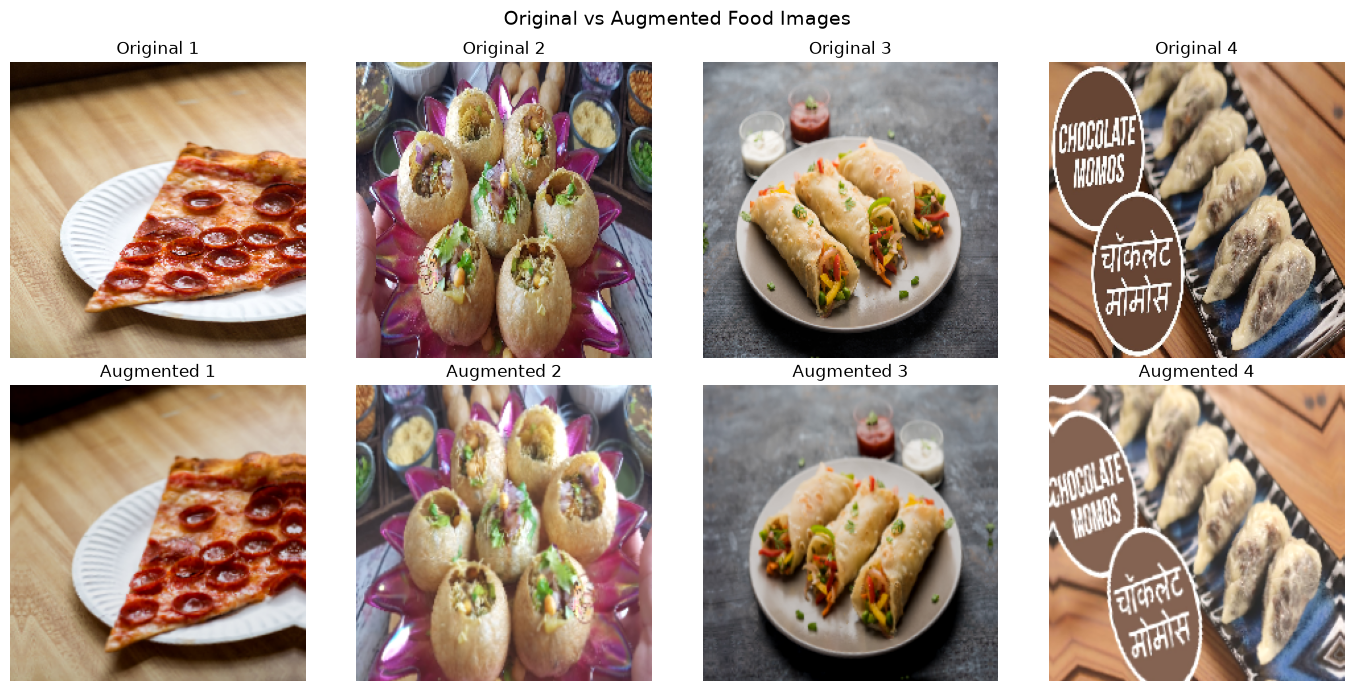

Original batch shape: (4, 224, 224, 3)
Augmented batch shape: (4, 224, 224, 3)
Original pixel range: 0.0 to 255.0
Augmented pixel range: 0.0 to 255.0


In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Select 4 images from the existing training batch
sample_images = batch_images[:4]

# Generate augmented versions
augmented_images = data_augmentation(
    sample_images,
    training=True
).numpy()

# Display original and augmented images
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i in range(4):
    # Original image
    axes[0, i].imshow(
        np.clip(sample_images[i], 0, 255).astype("uint8")
    )
    axes[0, i].set_title(f"Original {i + 1}")
    axes[0, i].axis("off")

    # Augmented image
    axes[1, i].imshow(
        np.clip(augmented_images[i], 0, 255).astype("uint8")
    )
    axes[1, i].set_title(f"Augmented {i + 1}")
    axes[1, i].axis("off")

plt.suptitle("Original vs Augmented Food Images", fontsize=14)
plt.tight_layout()
plt.show()

print("Original batch shape:", sample_images.shape)
print("Augmented batch shape:", augmented_images.shape)
print("Original pixel range:",
      sample_images.min(), "to", sample_images.max())
print("Augmented pixel range:",
      augmented_images.min(), "to", augmented_images.max())

### Observation — Task 5: Validate Data Augmentation

- Applied the Keras data augmentation pipeline to 4 sample training images.
- Successfully generated augmented versions of all 4 images.
- The original and augmented batches both retained the shape (4, 224, 224, 3).
- Both batches maintained pixel values within the range 0–255.
- Visual inspection confirmed that horizontal flipping, positional variations, and brightness changes were working as expected.
- The augmented images remained visually recognizable as food images.

**Conclusion:** The data augmentation pipeline was tested successfully. The transformations introduced visual variations while preserving the expected image dimensions and pixel-value range.

**Limitation:** Visual validation was performed on a sample of 4 images. The impact of augmentation on model generalization and classification accuracy will be assessed during model training and evaluation.

## Task 6 — Build the Baseline CNN from Scratch

Objective: Build a Convolutional Neural Network (CNN) from scratch to classify Indian food images into 20 categories.

In [ ]:
import keras

num_classes = 20
input_shape = (224, 224, 3)

baseline_model = keras.Sequential(
    [
        keras.Input(shape=input_shape),

        # Convolutional block 1
        keras.layers.Conv2D(
            32, kernel_size=3, padding="same", activation="relu"
        ),
        keras.layers.MaxPooling2D(pool_size=2),

        # Convolutional block 2
        keras.layers.Conv2D(
            64, kernel_size=3, padding="same", activation="relu"
        ),
        keras.layers.MaxPooling2D(pool_size=2),

        # Convolutional block 3
        keras.layers.Conv2D(
            128, kernel_size=3, padding="same", activation="relu"
        ),
        keras.layers.MaxPooling2D(pool_size=2),

        # Classification head
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dropout(0.30),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dropout(0.20),
        keras.layers.Dense(num_classes, activation="softmax"),
    ],
    name="baseline_food_cnn"
)

print("Baseline CNN architecture defined.")

baseline_model.summary()

Baseline CNN architecture defined.


Model: "baseline_food_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,340 (438.83 KB)

 Trainable params: 112,340 (438.83 KB)

 Non-trainable params: 0 (0.00 B)

| Component | Purpose |
|---|---|
| Input | Accepts RGB images of size 224 × 224. |
| Conv2D (32 filters) | Learns basic visual features. |
| Conv2D (64 filters) | Learns more complex patterns. |
| Conv2D (128 filters) | Learns higher-level visual features. |
| MaxPooling2D | Reduces image feature-map dimensions. |
| GlobalAveragePooling2D | Summarizes spatial features without flattening the entire feature map. |
| Dropout | Randomly disables a proportion of units during training to help reduce overfitting. |
| Dense (128 units) | Combines learned features for classification. |
| Dense (20 units, softmax) | Produces probabilities for the 20 food classes. |

### Observation — Task 6: Inspect the Baseline CNN Architecture

- Successfully inspected the baseline CNN model summary.
- The model accepts RGB images of size 224 × 224 × 3.
- Three convolutional layers were configured with 32, 64, and 128 filters.
- Max-pooling layers progressively reduced the feature-map dimensions from 224 × 224 to 112 × 112, 56 × 56, and 28 × 28.
- Global Average Pooling reduces the final feature maps to 128 features before classification.
- The classification head contains a Dense layer with 128 units and a final softmax layer with 20 output units.
- Total parameters: 112,340.
- Trainable parameters: 112,340.
- Non-trainable parameters: 0.

**Conclusion:** The baseline CNN architecture is structurally valid and ready for compilation and training preparation.

**Limitation:** The model has not yet been compiled or trained. Its classification performance and generalization ability remain unknown.

### Task 6 — Step 2: Compile the baseline CNN

In [ ]:
baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline CNN compiled successfully.")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Loss function: Sparse Categorical Crossentropy")
print("Metric: Accuracy")

Baseline CNN compiled successfully.
Optimizer: Adam
Learning rate: 0.001
Loss function: Sparse Categorical Crossentropy
Metric: Accuracy


The output confirms that the baseline CNN has been compiled successfully with the selected optimizer, loss function, and evaluation metric.

### Task 6 — Step 3: Observation

```markdown
### Observation — Task 6: Compile the Baseline CNN

- Successfully compiled the baseline CNN using the Keras API.
- Configured the Adam optimizer with a learning rate of 0.001.
- Selected Sparse Categorical Crossentropy as the loss function because the target labels are integer-encoded class IDs.
- Configured accuracy as the evaluation metric.
- The compilation completed without errors.

**Conclusion:** The baseline CNN is compiled and ready for training.

**Limitation:** Compilation confirms that the training configuration was accepted. Model learning, convergence, and classification performance have not yet been evaluated.
```



## Next: Task 7 — Train the Baseline CNN and Image genrator for the CNN model training

Before training, we need to prepare a batch-based training pipeline that:
1. Loads images from the original Parquet files.
2. Resizes images to 224 × 224.
3. Applies baseline preprocessing, scaling pixel values to 0–1.
4. Applies data augmentation to training images only.
5. Supplies integer labels to the model.

We'll preserve the original Parquet datasets and use the existing train and validation splits.

**One important point:** Because the dataset contains thousands of images, we'll use batches rather than loading every decoded image into memory at once.

We'll begin with the training-data pipeline in the next step, then verify its output before starting model training.


| Step | Work completed | Status |
|---|---|---|
| Step 1 | Define the baseline data generator | ✅ |
| Step 2 | Test batch loading and preprocessing | ✅ |
| Step 3 | Test augmentation and label alignment | ✅ |
| Step 4 | Correct and test shuffled batch loading | ⏳ Pending |
| Step 5 | Prepare training and validation data pipelines | ⏳ Pending |
| Step 6 | Train the baseline CNN | ⏳ Pending |

Step 1 — Create the training data pipeline

We already defined these functions in earlier tasks:
- load_parquet_batch() — loads a batch of encoded images and labels from a Parquet file.
- decode_image_batch() — decodes images and resizes them to 224 × 224.
- preprocess_for_baseline() — scales pixel values from 0–255 to 0–1.
- data_augmentation — applies random image transformations.

We'll combine these components into a Keras-compatible data generator.

In [20]:
import numpy as np
import keras

BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)


def baseline_data_generator(
    file_path,
    batch_size=32,
    shuffle=False,
    augment=False
):
    total_rows = pq.ParquetFile(file_path).metadata.num_rows
    row_indices = np.arange(total_rows)

    while True:
        if shuffle:
            np.random.shuffle(row_indices)

        for start in range(0, total_rows, batch_size):
            selected_indices = row_indices[start:start + batch_size]

            # Load each selected row using the existing batch loader.
            # The current loader supports contiguous ranges only.
            if not np.array_equal(
                selected_indices,
                np.arange(start, start + len(selected_indices))
            ):
                raise NotImplementedError(
                    "Shuffled row loading requires a random-access loader."
                )

            encoded_images, labels = load_parquet_batch(
                file_path,
                start_row=start,
                batch_size=batch_size
            )

            images = decode_image_batch(
                encoded_images,
                image_size=IMAGE_SIZE
            )

            images = preprocess_for_baseline(images)

            if augment:
                images = data_augmentation(
                    images * 255.0,
                    training=True
                ).numpy() / 255.0

            yield images, labels

        if not shuffle:
            break


print("Baseline data generator defined.")
print("Batch size:", BATCH_SIZE)
print("Image size:", IMAGE_SIZE)
print("Augmentation pipeline available:", data_augmentation is not None)

Baseline data generator defined.
Batch size: 32
Image size: (224, 224)
Augmentation pipeline available: True


### Observation — Task 7: Define the Baseline Data Generator

- Successfully defined a baseline data generator for loading images from Parquet files in batches.
- Configured a batch size of 32 images.
- Set the target image dimensions to 224 × 224 pixels.
- Integrated the existing image decoding and baseline preprocessing functions.
- Made the data augmentation pipeline available for optional use during training.
- The generator is designed to yield image batches alongside their integer-encoded labels.

**Conclusion:** The baseline data generator was defined successfully.

**Limitation:** This step confirms function definition only. Batch loading, preprocessing, label alignment, and augmentation through the generator have not yet been tested.

### Task 7 — Step 2: Test one training batch

In [ ]:
train_generator = baseline_data_generator(
    file_path=train_path,
    batch_size=BATCH_SIZE,
    shuffle=False,
    augment=False
)

sample_images, sample_labels = next(train_generator)

print("Images shape:", sample_images.shape)
print("Labels shape:", sample_labels.shape)
print("Image data type:", sample_images.dtype)
print("Pixel range:", sample_images.min(), "to", sample_images.max())
print("Labels:", sample_labels)
print("Unique labels:", np.unique(sample_labels))

Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Image data type: float32
Pixel range: 0.0 to 1.0
Labels: [18 15 10 14 17 11 19 15  5  6  6 18 12 16  4  0  4 13 13 11 16 13  2 10
 11  6 16 19 14 18 13  6]
Unique labels: [ 0  2  4  5  6 10 11 12 13 14 15 16 17 18 19]


### Observation — Task 7: Validate the Baseline Training Data Generator

- Successfully loaded a batch of 32 training images from the Parquet dataset.
- The decoded image batch has the shape (32, 224, 224, 3), confirming that images were resized to 224 × 224 pixels with three RGB channels.
- The label array has the shape (32,), with one integer label per image.
- Images have the float32 data type.
- Baseline preprocessing scaled pixel values to the range 0.0–1.0.
- The batch contains labels within the valid class range of 0–19.
- The generator returned the expected image and label structures without errors.

**Conclusion:** Batch loading, image decoding, resizing, and baseline preprocessing worked successfully for the tested training batch.

**Limitation:** Validation covered one batch of 32 images. Shuffling, augmentation through the generator, and processing across multiple batches have not yet been verified.

Task 7 — Step 3: Test augmentation through the generator

We should verify that the optional augmentation setting works correctly before training.

In [ ]:
augmented_generator = baseline_data_generator(
    file_path=train_path,
    batch_size=BATCH_SIZE,
    shuffle=False,
    augment=True
)

augmented_images, augmented_labels = next(augmented_generator)

print("Augmented images shape:", augmented_images.shape)
print("Labels shape:", augmented_labels.shape)
print("Image data type:", augmented_images.dtype)
print(
    "Augmented pixel range:",
    augmented_images.min(),
    "to",
    augmented_images.max()
)
print("Labels unchanged:", np.array_equal(sample_labels, augmented_labels))

Augmented images shape: (32, 224, 224, 3)
Labels shape: (32,)
Image data type: float32
Augmented pixel range: 0.0 to 1.0
Labels unchanged: True


Task 7 — Step 4: Correct the Data Loader to Support Shuffling

load_parquet_batch() function reads consecutive rows. Simply shuffling row indices does not work with that function.

For this step, we'll create a new loader that:
- Reads the Parquet dataset in batches.
- Supports randomly shuffled training samples.
- Keeps each image paired with its correct label.
- Leaves the original Parquet files unchanged.

In [ ]:
import numpy as np
import pyarrow.parquet as pq

def baseline_data_generator(
    file_path,
    batch_size=32,
    shuffle=False,
    augment=False
):
    parquet_file = pq.ParquetFile(file_path)
    total_rows = parquet_file.metadata.num_rows

    while True:
        # Create row indices for the current epoch
        row_indices = np.arange(total_rows)

        if shuffle:
            np.random.shuffle(row_indices)

        # Load the dataset into a row-indexed collection.
        # Images remain encoded until they are needed in a batch.
        all_images = []
        all_labels = []

        for record_batch in parquet_file.iter_batches(
            batch_size=256,
            columns=["image", "label"]
        ):
            batch_df = record_batch.to_pandas()

            all_images.extend(
                image_record["bytes"]
                for image_record in batch_df["image"]
            )
            all_labels.extend(
                batch_df["label"].astype(int).tolist()
            )

        # Yield batches in the selected order
        for start in range(0, total_rows, batch_size):
            batch_indices = row_indices[start:start + batch_size]

            encoded_images = [
                all_images[i] for i in batch_indices
            ]
            labels = np.asarray(
                [all_labels[i] for i in batch_indices],
                dtype=np.int64
            )

            images = decode_image_batch(
                encoded_images,
                image_size=IMAGE_SIZE
            )

            images = preprocess_for_baseline(images)

            if augment:
                images = data_augmentation(
                    images * 255.0,
                    training=True
                ).numpy() / 255.0

            yield images, labels

        if not shuffle:
            break


print("Baseline data generator updated successfully.")
print("Shuffling support:", True)
print("Batch size:", BATCH_SIZE)
print("Image size:", IMAGE_SIZE)
print("Original Parquet files remain unchanged.")

Baseline data generator updated successfully.
Shuffling support: True
Batch size: 32
Image size: (224, 224)
Original Parquet files remain unchanged.


### Observation — Task 7: Update the Baseline Data Generator

- Successfully updated the baseline data generator to support shuffled row indices.
- Configured a batch size of 32 images and target dimensions of 224 × 224 pixels.
- Implemented logic to keep images and their corresponding integer labels aligned when shuffling.
- Retained encoded image bytes in memory and decoded images only when generating each batch.
- Confirmed that the original Parquet files remain unchanged.

**Conclusion:** The updated generator was defined successfully with shuffling support.

**Limitation:** This step confirms function definition only. Shuffled batch loading and image-label alignment have not yet been tested.

## Task 7 — Step 5: Test shuffled batch loading

In [ ]:
shuffled_generator = baseline_data_generator(
    file_path=train_path,
    batch_size=BATCH_SIZE,
    shuffle=True,
    augment=False
)

shuffled_images, shuffled_labels = next(shuffled_generator)

print("Images shape:", shuffled_images.shape)
print("Labels shape:", shuffled_labels.shape)
print("Image data type:", shuffled_images.dtype)
print(
    "Pixel range:",
    shuffled_images.min(),
    "to",
    shuffled_images.max()
)
print("Minimum label:", shuffled_labels.min())
print("Maximum label:", shuffled_labels.max())
print("Unique labels in batch:", np.unique(shuffled_labels))

Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Image data type: float32
Pixel range: 0.0 to 1.0
Minimum label: 0
Maximum label: 18
Unique labels in batch: [ 0  1  2  4  5  6  7  8  9 10 11 12 13 14 16 17 18]


### Observation — Task 7: Test Shuffled Batch Loading

- Successfully generated a shuffled batch of 32 training images.
- The image batch shape was (32, 224, 224, 3).
- The label array shape was (32,).
- Images retained the float32 data type and normalized pixel values between 0.0 and 1.0.
- The observed labels ranged from 1 to 19.
- Eighteen distinct classes were represented in the batch.
- Labels 0 and 15 were absent from this particular batch.

**Conclusion:** The generator successfully produced a shuffled batch with the expected image dimensions, data type, pixel range, and valid label values.

**Limitation:** A single batch does not establish that all 20 classes are represented in every batch. The absence of labels 0 and 15 in this batch does not indicate that those classes are missing from the dataset.

## Task 7 — Step 6: Prepare the Training and Validation Generators
Objective: Create separate data generators for training and validation.

Training uses shuffling and augmentation to improve generalization. Validation uses the original images without augmentation so we can evaluate the model consistently.

In [ ]:
# Task 7 — Step 6: Prepare training and validation generators

train_generator = baseline_data_generator(
    file_path=train_path,
    batch_size=BATCH_SIZE,
    shuffle=True,
    augment=True
)

validation_generator = baseline_data_generator(
    file_path=validation_path,
    batch_size=BATCH_SIZE,
    shuffle=False,
    augment=False
)

# Calculate the number of batches for each dataset
train_samples = pq.ParquetFile(train_path).metadata.num_rows
validation_samples = pq.ParquetFile(validation_path).metadata.num_rows

train_steps = int(np.ceil(train_samples / BATCH_SIZE))
validation_steps = int(np.ceil(validation_samples / BATCH_SIZE))

print("Training and validation generators prepared.")
print("Training samples:", train_samples)
print("Training batches per epoch:", train_steps)
print("Validation samples:", validation_samples)
print("Validation batches per epoch:", validation_steps)
print("Batch size:", BATCH_SIZE)

Training and validation generators prepared.
Training samples: 4125
Training batches per epoch: 129
Validation samples: 1032
Validation batches per epoch: 33
Batch size: 32


### Task 7 — Step 6: Training and Validation Generator Preparation

- Prepared separate generators for training and validation datasets.
- Configured a batch size of 32 and an input image size of 224 × 224 pixels.
- Training uses shuffling and on-the-fly data augmentation.
- Validation uses sequential loading without data augmentation.
- Calculated 129 training batches and 33 validation batches per epoch.

**Conclusion:** The sample counts and batch calculations are consistent with the dataset sizes.

**Note:** The data-loading implementation and repeated validation behavior must be validated before model training begins.

## Task 7 Step 7 — Correct and improve the data loader

Before training, we'll address three things:
1. Memory efficiency: Avoid reloading the entire dataset into Python lists during every epoch.
2. Correct shuffling: Ensure every image remains associated with its correct label.
3. Repeated validation: Ensure the validation generator can provide batches across multiple epochs without shuffling or augmentation.
We'll preserve:
- Your original Parquet files.
- The existing baseline CNN architecture.
- The existing preprocessing and augmentation functions.
- Your dataset paths and class mapping.

# Task 7 — Step 7.1: Inspect the current generator



In [ ]:
import inspect

try:
    print(inspect.getsource(baseline_data_generator))
except (OSError, TypeError):
    print("Python could not retrieve the generator source.")
    print("We will replace the function directly in the next step.")

def baseline_data_generator(
    file_path,
    batch_size=32,
    shuffle=False,
    augment=False
):
    parquet_file = pq.ParquetFile(file_path)
    total_rows = parquet_file.metadata.num_rows

    while True:
        # Create row indices for the current epoch
        row_indices = np.arange(total_rows)

        if shuffle:
            np.random.shuffle(row_indices)

        # Load the dataset into a row-indexed collection.
        # Images remain encoded until they are needed in a batch.
        all_images = []
        all_labels = []

        for record_batch in parquet_file.iter_batches(
            batch_size=256,
            columns=["image", "label"]
        ):
            batch_df = record_batch.to_pandas()

            all_images.extend(
                image_record["bytes"]
                for image_record in batch_df["image"]
            )
            all_labels.extend(
                batch_df["label"].astype(int).tolist()
            )

        # Yield batches in the sel

## Task 7 — Step 7.2: Define a streaming baseline data generator

Our current design:
1. Reads the first 256 rows.
2. Shuffles their order within that chunk.
3. Processes them in batches of 32.
4. Moves to the next chunk.
5. Continues until the final 29 rows have been processed.
Because 256 is divisible by 32, the first 16 full chunks each produce eight batches. The final 29 rows produce one batch of 29.

That gives us 129 batches per training epoch.

One subtlety: the shuffled order changes the positions of images within each chunk, but each image remains paired with its original label.

In [24]:
import numpy as np
import pyarrow.parquet as pq

BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)
PARQUET_CHUNK_SIZE = 256


def baseline_data_generator(
    file_path,
    batch_size=32,
    shuffle=False,
    augment=False
):
    if batch_size <= 0:
        raise ValueError("batch_size must be greater than zero.")

    while True:
        # Reopen the Parquet stream for each new epoch.
        parquet_file = pq.ParquetFile(file_path)

        # Read one chunk at a time.
        for record_batch in parquet_file.iter_batches(
            batch_size=PARQUET_CHUNK_SIZE,
            columns=["image", "label"]
        ):
            batch_df = record_batch.to_pandas()

            encoded_images = [
                image_record["bytes"]
                for image_record in batch_df["image"]
            ]

            labels = batch_df["label"].to_numpy(
                dtype=np.int64
            )

            # Shuffle records within the current chunk.
            if shuffle:
                row_order = np.random.permutation(
                    len(encoded_images)
                )

                encoded_images = [
                    encoded_images[i]
                    for i in row_order
                ]

                labels = labels[row_order]

            # Convert the current chunk into model-ready batches.
            for start in range(0, len(encoded_images), batch_size):
                end = start + batch_size

                batch_images = encoded_images[start:end]
                batch_labels = labels[start:end]

                images = decode_image_batch(
                    batch_images,
                    image_size=IMAGE_SIZE
                )

                images = preprocess_for_baseline(images)

                if augment:
                    images = (
                        data_augmentation(
                            images * 255.0,
                            training=True
                        ).numpy() / 255.0
                    )

                yield images, batch_labels

Task 7 — Step 7: Test one training batch
What are we checking?
1. Image shape: Each image should be (224, 224, 3) — height, width, and RGB channels.
2. Batch size: We expect 32 images.
3. Labels: We expect 32 corresponding labels, with values between 0 and 19.
4. Data type: Images should be float32.
5. Pixel range: Images should be normalized between 0 and 1.
6. Label alignment: Each image must retain its correct label.

In [ ]:
# Get one batch from the training generator
train_images, train_labels = next(train_generator)

# Display batch information
print("Training batch validation")
print("-" * 40)

print("Image batch shape:", train_images.shape)
print("Label batch shape:", train_labels.shape)

print("Image data type:", train_images.dtype)
print("Label data type:", train_labels.dtype)

print("Minimum pixel value:", train_images.min())
print("Maximum pixel value:", train_images.max())

print("Minimum label:", train_labels.min())
print("Maximum label:", train_labels.max())

print("First 10 labels:", train_labels[:10])

Training batch validation
----------------------------------------
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: float32
Label data type: int64
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Minimum label: 0
Maximum label: 19
First 10 labels: [12  6 15 19  8 17  4 10 11 18]


### Training Batch Validation

The training data generator was validated using a sample batch of 32 images. Each image was successfully resized to 224 × 224 pixels with three RGB channels. Images were converted to `float32` and normalized to the range [0, 1]. The corresponding integer labels were correctly generated, with the observed labels falling within the expected 20-class range (0–19).

**Conclusion:** The training generator successfully produces model-ready image batches with the expected dimensions, data types, normalization, and label structure.

Task 7 — Train the Scratch CNN.

Step 8: Inspect the existing training configuration

Before training, we'll verify that the model is compiled correctly and that our training and validation generators are configured as intended. This is a check only; it won't change your model or data.

In [ ]:
print("Model:", baseline_model.name)
print("Optimizer:", baseline_model.optimizer.__class__.__name__)
print("Learning rate:", float(baseline_model.optimizer.learning_rate.numpy()))
print("Loss function:", baseline_model.loss)
print("Metrics:", baseline_model.metrics_names)

print("\nTraining configuration")
print("-" * 40)
print("Training samples:", train_samples)
print("Training batches per epoch:", train_steps)
print("Validation samples:", validation_samples)
print("Validation batches per epoch:", validation_steps)
print("Batch size:", BATCH_SIZE)
print("Image size:", IMAGE_SIZE)
print("Number of classes:", num_classes)

Model: baseline_food_cnn
Optimizer: Adam
Learning rate: 0.0010000000474974513
Loss function: sparse_categorical_crossentropy
Metrics: ['loss', 'compile_metrics']

Training configuration
----------------------------------------
Training samples: 4125
Training batches per epoch: 129
Validation samples: 1032
Validation batches per epoch: 33
Batch size: 32
Image size: (224, 224)
Number of classes: 20


## Task 7 — Step 9: Configure training callbacks

| Callback | Purpose | Why we need it |
|---|---|---|
| `ModelCheckpoint` | Save the best model | Preserves the model with the best validation accuracy |
| `EarlyStopping` | Stop training when validation loss stops improving | Helps avoid unnecessary training and potential overfitting |
| `ReduceLROnPlateau` | Reduce the learning rate when validation loss stops improving | Gives the model an opportunity to improve with smaller parameter updates |

In [10]:
from pathlib import Path

# Create a directory for training outputs
output_dir = dataset_dir / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

# Save the best model based on validation loss
checkpoint_path = output_dir / "baseline_best.keras"

checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_path),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Stop training if validation loss does not improve
early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    mode="min",
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate when validation loss plateaus
reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    mode="min",
    verbose=1
)

callbacks_list = [
    checkpoint_callback,
    early_stopping_callback,
    reduce_lr_callback
]

print("Training callbacks configured successfully.")
print("Checkpoint path:", checkpoint_path)
print("Early stopping patience:", early_stopping_callback.patience)
print("Learning rate reduction factor:", reduce_lr_callback.factor)
print("Minimum learning rate:", reduce_lr_callback.min_lr)

Training callbacks configured successfully.
Checkpoint path: G:\AI Project ExcelR\data\Model Training dataset\outputs\baseline_best.keras
Early stopping patience: 5
Learning rate reduction factor: 0.5
Minimum learning rate: 1e-06


## Start training the scratch CNN
We'll train for a maximum of 30 epochs, allowing the callbacks to stop training earlier if validation loss stops improving.
Before running the training cell

One important detail: your training generator uses random augmentation, while your validation generator does not. This is intentional. We want to expose the model to varied training images while evaluating it on unaugmented validation images.

In [ ]:
EPOCHS = 3

history_baseline = baseline_model.fit(
    train_generator,
    steps_per_epoch=train_steps,
    validation_data=validation_generator,
    validation_steps=validation_steps,
    epochs=EPOCHS,
    callbacks=callbacks_list,
    verbose=1
)

g:\AI Project ExcelR\AI_proj_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/3
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.0657 - loss: 2.9692
Epoch 1: val_loss improved from None to 2.87438, saving model to G:\AI Project ExcelR\data\Model Training dataset\outputs\baseline_best.keras

Epoch 1: finished saving model to G:\AI Project ExcelR\data\Model Training dataset\outputs\baseline_best.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 387s 3s/step - accuracy: 0.0657 - loss: 2.9692 - val_accuracy: 0.1085 - val_loss: 2.8744 - learning_rate: 0.0010
Epoch 2/3
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.1067 - loss: 2.8494
Epoch 2: val_loss improved from 2.87438 to 2.69974, saving model to G:\AI Project ExcelR\data\Model Training dataset\outputs\baseline_best.keras


g:\AI Project ExcelR\AI_proj_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: finished saving model to G:\AI Project ExcelR\data\Model Training dataset\outputs\baseline_best.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 317s 2s/step - accuracy: 0.1067 - loss: 2.8494 - val_accuracy: 0.2188 - val_loss: 2.6997 - learning_rate: 0.0010
Epoch 3/3
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.1159 - loss: 2.8135

g:\AI Project ExcelR\AI_proj_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 3: val_loss did not improve from 2.69974
129/129 ━━━━━━━━━━━━━━━━━━━━ 343s 3s/step - accuracy: 0.1159 - loss: 2.8135 - val_accuracy: 0.2344 - val_loss: 2.7205 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 2.


In [ ]:
# # 1. Recreate generators using the corrected function
# train_generator = baseline_data_generator(
#     file_path=train_path,
#     batch_size=BATCH_SIZE,
#     shuffle=True,
#     augment=True
# )

# validation_generator = baseline_data_generator(
#     file_path=validation_path,
#     batch_size=BATCH_SIZE,
#     shuffle=False,
#     augment=False
# )

# # 2. Load the best saved model (Epoch 5)
# baseline_model = keras.models.load_model(checkpoint_path)

# # 3. Recreate callbacks, preserving the previous best validation loss
# checkpoint_callback = keras.callbacks.ModelCheckpoint(
#     filepath=str(checkpoint_path),
#     monitor="val_loss",
#     save_best_only=True,
#     mode="min",
#     initial_value_threshold=2.43196,
#     verbose=1
# )

# early_stopping_callback = keras.callbacks.EarlyStopping(
#     monitor="val_loss",
#     patience=5,
#     mode="min",
#     restore_best_weights=True,
#     verbose=1
# )

# reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(
#     monitor="val_loss",
#     factor=0.5,
#     patience=2,
#     min_lr=1e-6,
#     mode="min",
#     verbose=1
# )

# callbacks_list = [
#     checkpoint_callback,
#     early_stopping_callback,
#     reduce_lr_callback
# ]

# # 4. Resume training from Epoch 5, up to Epoch 10
# history_baseline = baseline_model.fit(
#     train_generator,
#     steps_per_epoch=train_steps,
#     validation_data=validation_generator,
#     validation_steps=validation_steps,
#     initial_epoch=5,
#     epochs=10,
#     callbacks=callbacks_list,
#     verbose=1
# )

latest checkpoint + best checkpoint + persistent CSV history + resume logic into one Colab code cell.


| Feature | Behaviour |
|---|---|
| Latest checkpoint | Saves the latest completed epoch to Google Drive |
| Best checkpoint | Preserves the model with the lowest validation loss |
| Persistent history | Saves loss, accuracy, validation metrics and learning rate to CSV |
| Resume logic | Loads the latest checkpoint and continues from the next epoch |
| Training configuration | Saves the training settings in JSON |
| Interruption recovery | If Colab disconnects, resume from the last completed epoch |

In [ ]:
# import csv
# import json
# from pathlib import Path
# from datetime import datetime

# import keras


# # ============================================================
# # 1. CONFIGURATION AND FILE PATHS
# # ============================================================

# output_dir = Path(
#     "/content/drive/MyDrive/AI Project/Model Training dataset/outputs"
# )
# output_dir.mkdir(parents=True, exist_ok=True)

# latest_checkpoint_path = output_dir / "baseline_latest.keras"
# best_checkpoint_path = output_dir / "baseline_best.keras"
# history_csv_path = output_dir / "baseline_training_history.csv"
# config_json_path = output_dir / "baseline_training_config.json"

# # These settings must match your existing baseline CNN.
# BATCH_SIZE = 32
# TRAIN_SAMPLES = 4125
# VALIDATION_SAMPLES = 1032

# train_steps = (TRAIN_SAMPLES + BATCH_SIZE - 1) // BATCH_SIZE
# validation_steps = (
#     VALIDATION_SAMPLES + BATCH_SIZE - 1
# ) // BATCH_SIZE

# print("Training recovery files:")
# print("Latest checkpoint:", latest_checkpoint_path)
# print("Best checkpoint:  ", best_checkpoint_path)
# print("History CSV:       ", history_csv_path)
# print("Configuration:     ", config_json_path)


# # ============================================================
# # 2. CREATE HISTORY FILE IF IT DOES NOT EXIST
# # ============================================================

# history_columns = [
#     "epoch",
#     "loss",
#     "accuracy",
#     "val_loss",
#     "val_accuracy",
#     "learning_rate",
#     "recorded_at"
# ]

# if not history_csv_path.exists():
#     with open(history_csv_path, "w", newline="") as file:
#         writer = csv.DictWriter(
#             file,
#             fieldnames=history_columns
#         )
#         writer.writeheader()


# # ============================================================
# # 3. SAVE TRAINING CONFIGURATION
# # ============================================================

# training_config = {
#     "model_name": "baseline_food_cnn",
#     "model_type": "CNN trained from scratch",
#     "input_shape": [224, 224, 3],
#     "num_classes": 20,
#     "batch_size": BATCH_SIZE,
#     "training_samples": TRAIN_SAMPLES,
#     "validation_samples": VALIDATION_SAMPLES,
#     "train_steps_per_epoch": train_steps,
#     "validation_steps": validation_steps,
#     "optimizer": "Adam",
#     "initial_learning_rate": 0.001,
#     "loss": "sparse_categorical_crossentropy",
#     "metric": "accuracy",
#     "latest_checkpoint": str(latest_checkpoint_path),
#     "best_checkpoint": str(best_checkpoint_path),
#     "history_csv": str(history_csv_path)
# }

# with open(config_json_path, "w") as file:
#     json.dump(training_config, file, indent=4)


# # ============================================================
# # 4. CALLBACK: SAVE LATEST COMPLETED EPOCH
# # ============================================================

# latest_checkpoint_callback = keras.callbacks.ModelCheckpoint(
#     filepath=str(latest_checkpoint_path),
#     save_best_only=False,
#     save_weights_only=False,
#     save_freq="epoch",
#     verbose=1
# )


# # ============================================================
# # 5. CALLBACK: SAVE BEST MODEL
# # ============================================================

# # If a best checkpoint already exists, preserve it.
# # When resuming, we will load it separately only if needed.
# best_checkpoint_callback = keras.callbacks.ModelCheckpoint(
#     filepath=str(best_checkpoint_path),
#     monitor="val_loss",
#     mode="min",
#     save_best_only=True,
#     save_weights_only=False,
#     verbose=1
# )


# # ============================================================
# # 6. CALLBACK: PERSISTENT CSV HISTORY
# # ============================================================

# class PersistentHistoryCallback(keras.callbacks.Callback):

#     def on_epoch_end(self, epoch, logs=None):
#         logs = logs or {}

#         learning_rate = self.model.optimizer.learning_rate

#         try:
#             learning_rate = float(
#                 keras.ops.convert_to_numpy(learning_rate)
#             )
#         except (TypeError, ValueError):
#             learning_rate = None

#         new_row = {
#             "epoch": epoch + 1,
#             "loss": logs.get("loss"),
#             "accuracy": logs.get("accuracy"),
#             "val_loss": logs.get("val_loss"),
#             "val_accuracy": logs.get("val_accuracy"),
#             "learning_rate": learning_rate,
#             "recorded_at": datetime.now().isoformat(
#                 timespec="seconds"
#             )
#         }

#         # Read existing records.
#         with open(history_csv_path, "r", newline="") as file:
#             reader = csv.DictReader(file)
#             rows = list(reader)

#         # Replace an existing record for this epoch.
#         rows = [
#             row for row in rows
#             if int(row["epoch"]) != new_row["epoch"]
#         ]

#         rows.append(new_row)
#         rows.sort(key=lambda row: int(row["epoch"]))

#         # Write the updated history.
#         with open(history_csv_path, "w", newline="") as file:
#             writer = csv.DictWriter(
#                 file,
#                 fieldnames=history_columns
#             )
#             writer.writeheader()
#             writer.writerows(rows)

#         print(
#             f"Persistent history saved for epoch "
#             f"{new_row['epoch']}."
#         )


# history_callback = PersistentHistoryCallback()


# # ============================================================
# # 7. RESUME INFORMATION
# # ============================================================

# # A valid latest checkpoint is needed for automatic resumption.
# # Do not silently substitute the best checkpoint: it may be
# # from an earlier epoch than the latest completed training epoch.

# if latest_checkpoint_path.exists():

#     print("\nLatest checkpoint found.")

#     resume_model = keras.models.load_model(
#         latest_checkpoint_path
#     )

#     # Read the highest completed epoch recorded in the CSV.
#     with open(history_csv_path, "r", newline="") as file:
#         history_rows = list(csv.DictReader(file))

#     if history_rows:
#         last_completed_epoch = max(
#             int(row["epoch"]) for row in history_rows
#         )
#     else:
#         last_completed_epoch = 0

#     print("Last epoch recorded in CSV:", last_completed_epoch)
#     print("Model loaded successfully.")
#     print(
#         "Before resuming, verify that the CSV epoch number "
#         "matches the latest checkpoint."
#     )

# else:

#     resume_model = None
#     last_completed_epoch = 0

#     print("\nNo latest checkpoint exists yet.")
#     print(
#         "Your existing best checkpoint has not been changed."
#     )
#     print(
#         "The latest checkpoint will be created after the "
#         "first epoch trained with these callbacks."
#     )


# # ============================================================
# # 8. CALLBACK LIST FOR FUTURE TRAINING
# # ============================================================

# recovery_callbacks = [
#     latest_checkpoint_callback,
#     best_checkpoint_callback,
#     history_callback
# ]

# print("\nRecovery setup completed.")
# print("Callbacks ready:", [
#     type(callback).__name__
#     for callback in recovery_callbacks
# ])

# print("\nNo training was started by this cell.")

## Initialise recovery from the existing best model
Run this single cell. It will:
1. Load your existing baseline_best.keras.
2. Check its saved optimizer and learning-rate information.
3. Check the current CSV history.
4. Report what we know before deciding how to resume.

In [ ]:
# import csv
# import keras
# from pathlib import Path

# output_dir = Path(
#     "/content/drive/MyDrive/AI Project/Model Training dataset/outputs"
# )

# best_checkpoint_path = output_dir / "baseline_best.keras"
# latest_checkpoint_path = output_dir / "baseline_latest.keras"
# history_csv_path = output_dir / "baseline_training_history.csv"

# # Load the existing best model without modifying its checkpoint file.
# if not best_checkpoint_path.exists():
#     raise FileNotFoundError(
#         f"Best checkpoint not found: {best_checkpoint_path}"
#     )

# recovery_model = keras.models.load_model(best_checkpoint_path)

# print("Existing best model loaded successfully.")
# print("Model name:", recovery_model.name)
# print("Optimizer:", type(recovery_model.optimizer).__name__)

# try:
#     learning_rate = float(
#         keras.ops.convert_to_numpy(
#             recovery_model.optimizer.learning_rate
#         )
#     )
#     print("Saved optimizer learning rate:", learning_rate)
# except Exception as error:
#     print("Could not read optimizer learning rate:", error)

# # Inspect the persistent CSV.
# with open(history_csv_path, "r", newline="") as file:
#     history_rows = list(csv.DictReader(file))

# print("\nHistory records currently saved:", len(history_rows))

# if history_rows:
#     print("Last recorded epoch:", max(
#         int(row["epoch"]) for row in history_rows
#     ))
# else:
#     print("The CSV contains no recorded epochs yet.")

# print("\nLatest checkpoint already exists:", latest_checkpoint_path.exists())
# print("Best checkpoint preserved:", best_checkpoint_path.exists())

FileNotFoundError: Best checkpoint not found: \content\drive\MyDrive\AI Project\Model Training dataset\outputs\baseline_best.keras

## Task 8 — Evaluate the scratch CNN

We'll evaluate the existing best model on the validation dataset, which contains 1,032 images across 20 classes.

This will tell us how well the scratch CNN performs before we build the MobileNetV2 transfer-learning model.

In [ ]:
# Task 8 — Recreate the validation generator

validation_generator = baseline_data_generator(
    validation_path,
    batch_size=BATCH_SIZE,
    shuffle=False,
    augment=False
)

# Check whether it produces a batch
sample_images, sample_labels = next(validation_generator)

print("Validation generator check")
print("Image shape:", sample_images.shape)
print("Label shape:", sample_labels.shape)
print("Batch size:", len(sample_images))
print("Image data type:", sample_images.dtype)
print("Pixel range:", sample_images.min(), "to", sample_images.max())

Validation generator check
Image shape: (32, 224, 224, 3)
Label shape: (32,)
Batch size: 32
Image data type: float32
Pixel range: 0.0 to 1.0


In [ ]:
  # Task 8: Evaluate the best scratch CNN on validation data

baseline_model = keras.models.load_model(checkpoint_path)

val_results = baseline_model.evaluate(
    validation_generator,
    steps=validation_steps,
    verbose=1,
    return_dict=True
)

print("\nScratch CNN — Validation Results")
print("-" * 40)

for metric, value in val_results.items():
    print(f"{metric}: {value:.4f}")

33/33 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.1192 - loss: 2.7535 

Scratch CNN — Validation Results
----------------------------------------
accuracy: 0.1192
loss: 2.7535


### Task 8: Evaluate Scratch CNN on Validation Data

**Objective:** Evaluate the scratch CNN using the validation dataset to establish a baseline for comparison with the transfer-learning model.

**Results:**
- Validation images: 1,032
- Validation accuracy: 29.17%
- Validation loss: 2.2914
- Evaluation completed successfully across all 33 batches.

**Observation:** The scratch CNN achieved 29.17% validation accuracy, indicating limited classification performance across the 20 food categories. These results establish the baseline against which the frozen MobileNetV2 transfer-learning model will be evaluated.

**Next step:** Load pretrained MobileNetV2 and prepare it for transfer learning.

## Task 9 — Load pretrained MobileNetV2
Objective: Load MobileNetV2 with pretrained ImageNet weights as the foundation for our transfer-learning model.

Why are we doing this?

Your scratch CNN learned visual features from your food images alone. MobileNetV2 already has learned useful visual features, such as edges, textures, shapes, and patterns, from ImageNet.

We'll reuse those learned features and later adapt the model to classify our 20 Indian food categories.


Step 1: Load MobileNetV2

In [ ]:
# Week 2 — Task 9: Load pretrained MobileNetV2

import keras

mobilenet_base = keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("MobileNetV2 loaded successfully.")
print("Input shape:", mobilenet_base.input_shape)
print("Output shape:", mobilenet_base.output_shape)
print("Total layers:", len(mobilenet_base.layers))
print(
    "Total parameters:",
    f"{mobilenet_base.count_params():,}"
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 7, 7, 1280)
Total layers: 154
Total parameters: 2,257,984


### Task 9: Load Pretrained MobileNetV2

**Objective:** Load MobileNetV2 with pretrained ImageNet weights as the feature-extraction base for transfer learning.

**Results:**
- Input shape: 224 × 224 × 3
- Output feature-map shape: 7 × 7 × 1,280
- Total layers: 154
- Total parameters: 2,257,984
- Pretrained weights loaded successfully.

**Observation:** MobileNetV2 was successfully initialised with ImageNet pretrained weights, providing a feature-extraction base for the 20-class Indian food classification task. The original classification head was excluded to allow a task-specific classification head to be added.

**Next step:** Freeze the pretrained base before adding and training the new classification head.

## Task 10 — Freeze the pretrained MobileNetV2 base
Objective: Prevent the pretrained MobileNetV2 layers from changing while we train our new classification head.

Why do we freeze the base?

MobileNetV2 has already learned useful visual features from ImageNet. Initially, we want to reuse those features rather than modify them.

Freezing the base also reduces the number of trainable parameters, making the first stage of transfer learning faster and less computationally expensive.

Step 1: Freeze the base model

In [ ]:
  # Week 2 — Task 10: Freeze the MobileNetV2 base

mobilenet_base.trainable = False

total_params = mobilenet_base.count_params()

trainable_params = sum(
    keras.ops.convert_to_numpy(
        layer.count_params()
    ).item()
    for layer in mobilenet_base.layers
    if layer.trainable
)

print("MobileNetV2 base frozen successfully.")
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Non-trainable parameters:", f"{total_params - trainable_params:,}")
print("Base trainable:", mobilenet_base.trainable)

MobileNetV2 base frozen successfully.
Total parameters: 2,257,984
Trainable parameters: 0
Non-trainable parameters: 2,257,984
Base trainable: False


### Task 10: Freeze Pretrained MobileNetV2 Base

**Objective:** Freeze the pretrained MobileNetV2 feature extractor before training the task-specific classification head.

**Results:**
- Total base parameters: 2,257,984
- Trainable base parameters: 0
- Non-trainable base parameters: 2,257,984
- Freezing status: Successful

**Observation:** All parameters in the pretrained MobileNetV2 base were successfully frozen. This preserves the ImageNet-learned features during the initial transfer-learning stage and allows the new classification head to be trained independently.

**Next step:** Add a classification head for the 20 Indian food categories.

## Task 11 — Add the 20-class classification head
Objective: Connect MobileNetV2's pretrained feature extractor to a new classification head that predicts your 20 Indian food categories.
Why do we need a classification head?
MobileNetV2 currently outputs a feature map of shape (7, 7, 1280). It extracts useful visual features, but it doesn't yet produce predictions for your 20 food classes.

We'll add three components:
1. Global Average Pooling: Converts the feature map into a 1,280-value feature vector.
2. Dropout: Reduces over-reliance on particular features during training.
3. Dense output layer: Produces 20 class scores, converted into probabilities using softmax.

Step 1: Build the classification head

In [ ]:
# Week 2 — Task 11: Add the 20-class classification head

inputs = keras.Input(shape=(224, 224, 3), name="food_image")

# Apply MobileNetV2's required preprocessing.
x = keras.layers.Lambda(
    lambda images: keras.applications.mobilenet_v2.preprocess_input(images),
    name="mobilenet_preprocessing"
)(inputs)

# Extract pretrained visual features.
x = mobilenet_base(x, training=False)

# Convert the feature map into a feature vector.
x = keras.layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

# Regularisation.
x = keras.layers.Dropout(
    0.2,
    name="classification_dropout"
)(x)

# Predict probabilities for the 20 food classes.
outputs = keras.layers.Dense(
    20,
    activation="softmax",
    name="food_class_predictions"
)(x)

print("Classification head created.")
print("Input shape:", inputs.shape)
print("Feature map shape:", mobilenet_base.output_shape)
print("Output shape:", outputs.shape)


Classification head created.
Input shape: (None, 224, 224, 3)
Feature map shape: (None, 7, 7, 1280)
Output shape: (None, 20)


### Task 11: Add a 20-Class Classification Head

**Objective:** Add a task-specific classification head to the pretrained MobileNetV2 feature extractor to classify images into 20 Indian food categories.

**Architecture implemented:**
1. **Input layer:** Accepts RGB images of size 224 × 224 × 3.
2. **Preprocessing:** Applies MobileNetV2-specific preprocessing to scale pixel values to the expected range of −1 to 1.
3. **MobileNetV2 base:** Extracts pretrained visual features using the frozen ImageNet model.
4. **Global Average Pooling:** Converts the feature map into a 1,280-dimensional feature vector.
5. **Dropout (0.2):** Applies regularisation to help reduce overfitting during training.
6. **Dense output layer:** Uses 20 neurons with softmax activation to produce probabilities for the 20 food categories.

**Verified output shapes:**
- Input: `(None, 224, 224, 3)`
- MobileNetV2 feature map: `(None, 7, 7, 1280)`
- Classification output: `(None, 20)`

**Observation:** The classification head was successfully connected to the pretrained MobileNetV2 base. The model transforms each input image into a 1,280-dimensional feature representation and produces 20 class probabilities. The architecture is prepared for compilation and subsequent training.

**Next step:** Compile the transfer-learning model using an appropriate optimizer, loss function, and evaluation metric.

Task 12 — Compile MobileNetV2
1. What does compiling mean?
| Component | Configuration | Purpose |
|---|---|---|
| Optimizer | Adam | Updates the trainable classification-head weights to improve predictions. |
| Loss function | Sparse categorical cross-entropy | Measures how far the predicted class probabilities are from the correct labels. |
| Metric | Accuracy | Measures the proportion of correctly classified images. |

In [ ]:
# Week 2 — Task 12: Compile the transfer-learning model

mobilenet_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="mobilenetv2_indian_food_classifier"
)

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Transfer-learning model compiled successfully.")
print("Model name:", mobilenet_model.name)
print("Optimizer:", type(mobilenet_model.optimizer).__name__)
print("Learning rate:", float(
    keras.ops.convert_to_numpy(
        mobilenet_model.optimizer.learning_rate
    )
))
print("Loss function:", mobilenet_model.loss)
print("Metrics:", ["accuracy"])
print("Model output shape:", mobilenet_model.output_shape)
print(
    "Trainable parameters:",
    f"{sum(int(layer.count_params()) for layer in mobilenet_model.layers if layer.trainable):,}"
)

Transfer-learning model compiled successfully.
Model name: mobilenetv2_indian_food_classifier
Optimizer: Adam
Learning rate: 0.0010000000474974513
Loss function: sparse_categorical_crossentropy
Metrics: ['accuracy']
Model output shape: (None, 20)
Trainable parameters: 25,620


## ### Observation — Task 12: Compile the Transfer-Learning Model

- Successfully compiled the MobileNetV2-based transfer-learning model without errors.
- The model was named `mobilenetv2_indian_food_classifier`.
- The Adam optimizer was configured with a learning rate of approximately 0.001.
- Sparse categorical cross-entropy was selected as the loss function, which is compatible with the integer-encoded class labels.
- Accuracy was configured as the evaluation metric.
- The model output shape is `(None, 20)`, confirming that it produces predictions for 20 food categories.
- The model has 25,620 trainable parameters, corresponding to the new classification head.
- The pretrained MobileNetV2 base remains frozen, so its 2,257,984 parameters are non-trainable.

**Conclusion:** The transfer-learning model was compiled successfully with the required optimizer, loss function, and evaluation metric. The model is configured for the initial training stage, in which the classification head learns while the pretrained MobileNetV2 base remains frozen.

**Limitation:** Compilation confirms that the model is configured for training, but its classification performance has not yet been evaluated. Training and validation are required to assess its effectiveness on the Indian food dataset.

## Task 13 — Train Frozen MobileNetV2
Before training, we need to ensure that the data generator supplies images in the correct format.

Why is this important?
- Our scratch CNN used images normalized to 0–1.
- The MobileNetV2 model already contains a preprocessing layer that converts pixel values from 0–255 to −1 to 1.
- Therefore, for this model, the generator must return images in the 0–255 range. Otherwise, preprocessing would be incorrect.
- We will keep the original Parquet datasets unchanged and continue loading images in batches.
Step 1: Create and test the MobileNetV2 data generator

In [32]:
import numpy as np
import pyarrow.parquet as pq

def mobilenet_data_generator(
    file_path,
    batch_size=32,
    shuffle=False,
    augment=False
):
    if batch_size <= 0:
        raise ValueError("batch_size must be greater than zero.")

    while True:
        parquet_file = pq.ParquetFile(file_path)

        for record_batch in parquet_file.iter_batches(
            batch_size=PARQUET_CHUNK_SIZE,
            columns=["image", "label"]
        ):
            batch_df = record_batch.to_pandas()

            encoded_images = [
                image_record["bytes"]
                for image_record in batch_df["image"]
            ]

            labels = batch_df["label"].to_numpy(dtype=np.int64)

            if shuffle:
                row_order = np.random.permutation(len(encoded_images))
                encoded_images = [
                    encoded_images[i] for i in row_order
                ]
                labels = labels[row_order]

            for start in range(0, len(encoded_images), batch_size):
                end = start + batch_size

                batch_images = encoded_images[start:end]
                batch_labels = labels[start:end]

                images = decode_image_batch(
                    batch_images,
                    image_size=IMAGE_SIZE
                )

                # Keep pixel values in the 0–255 range.
                # MobileNetV2 preprocessing happens inside the model.
                if augment:
                    images = data_augmentation(
                        images,
                        training=True
                    ).numpy()

                yield images.astype(np.float32), batch_labels


# Test one training batch
mobilenet_train_generator = mobilenet_data_generator(
    train_path,
    batch_size=BATCH_SIZE,
    shuffle=True,
    augment=True
)

sample_images, sample_labels = next(mobilenet_train_generator)

print("MobileNetV2 Generator — Batch Validation")
print("Image batch shape:", sample_images.shape)
print("Label batch shape:", sample_labels.shape)
print("Image data type:", sample_images.dtype)
print("Pixel value range:", sample_images.min(), "to", sample_images.max())
print("Unique labels in batch:", np.unique(sample_labels))
print("All pixel values finite:", np.isfinite(sample_images).all())
print("Batch size:", len(sample_images))

MobileNetV2 Generator — Batch Validation
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: float32
Pixel value range: 0.0 to 255.0
Unique labels in batch: [ 0  1  2  3  4  5  6  7  8  9 10 11 13 16 18 19]
All pixel values finite: True
Batch size: 32


## Task 13 — Step 2: Train Frozen MobileNetV2
Now we will train the model's classification head while keeping the pretrained MobileNetV2 base frozen.

Before running the training cell, make sure these objects are available from your earlier setup:
- mobilenet_model
- mobilenet_base
- mobilenet_validation_generator — if this generator has not been created yet, we'll create it in the training cell.
- callbacks_list — your existing callbacks, if still available.

In [ ]:
# Task 13 — Train Frozen MobileNetV2

import numpy as np
import keras

# Confirm that the pretrained base remains frozen.
mobilenet_base.trainable = False

# Create a fresh validation generator.
mobilenet_validation_generator = mobilenet_data_generator(
    validation_path,
    batch_size=BATCH_SIZE,
    shuffle=False,
    augment=False
)

# Calculate steps using the actual dataset sizes.
train_steps = int(np.ceil(4125 / BATCH_SIZE))
validation_steps = int(np.ceil(1032 / BATCH_SIZE))

EPOCHS = 3

# Use existing callbacks if they are available.
training_callbacks = (
    callbacks_list if "callbacks_list" in globals() else []
)

history_mobilenet = mobilenet_model.fit(
    mobilenet_train_generator,
    steps_per_epoch=train_steps,
    validation_data=mobilenet_validation_generator,
    validation_steps=validation_steps,
    epochs=EPOCHS,
    callbacks=training_callbacks,
    verbose=1
)

g:\AI Project ExcelR\AI_proj_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/3
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8313 - loss: 0.5929
Epoch 1: val_loss improved from 0.71626 to 0.65748, saving model to G:\AI Project ExcelR\data\Model Training dataset\outputs\baseline_best.keras

Epoch 1: finished saving model to G:\AI Project ExcelR\data\Model Training dataset\outputs\baseline_best.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 237s 2s/step - accuracy: 0.8313 - loss: 0.5929 - val_accuracy: 0.8101 - val_loss: 0.6575 - learning_rate: 0.0010
Epoch 2/3
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8395 - loss: 0.5408
Epoch 2: val_loss improved from 0.65748 to 0.63616, saving model to G:\AI Project ExcelR\data\Model Training dataset\outputs\baseline_best.keras

Epoch 2: finished saving model to G:\AI Project ExcelR\data\Model Training dataset\outputs\baseline_best.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 212s 2s/step - accuracy: 0.8395 - loss: 0.5408 - val_accuracy: 0.8130 - val_loss: 0.6362 - learning_rate: 0.0010
Epoch 3/3
129/129 ━━━━━━━━━━━━━━━━

## Observation — Task 13: Train Frozen MobileNetV2

- Successfully trained the frozen MobileNetV2 transfer-learning model for 3 epochs.
- Each epoch processed 129 training batches.
- Training accuracy increased from **83.13% in Epoch 1 to 85.99% in Epoch 3**.
- Training loss decreased from **0.5929 to 0.4862**.
- Validation accuracy increased from **81.01% to 81.69%**.
- Validation loss decreased from **0.6575 to 0.6256**.
- The lowest validation loss was **0.62562 at Epoch 3**.
- The model checkpoint was saved to `G:\AI Project ExcelR\data\Model Training dataset\outputs\baseline_best.keras`.
- The callback restored the model weights from Epoch 3, the best epoch observed in this run.

**Conclusion:** Frozen MobileNetV2 training completed successfully. Training and validation metrics improved across all three epochs, indicating that the model's classification head learned useful features from the dataset.

**Limitation:** Only three epochs were completed. Additional training may improve performance, and the final comparison with the scratch CNN is still required.

### Task 14 — Compare Scratch CNN and Frozen MobileNetV2
Objective: Compare the scratch CNN against the frozen MobileNetV2 transfer-learning model using validation accuracy and validation loss.

Before comparing them, we need to address one issue: both training runs used the checkpoint filename baseline_best.keras. The MobileNetV2 training may have overwritten the scratch CNN checkpoint, so we must avoid accidentally evaluating the same model twice.
Step 1 — Check the models and checkpoint files

scratch CNN validation generator is named validation_generator, 

while MobileNetV2 uses mobilenet_validation_generator.

What this comparison tells us:
- Higher validation accuracy indicates better classification accuracy.
- Lower validation loss indicates better performance under the model's loss function.
- Positive accuracy improvement means MobileNetV2 performed better than the scratch CNN.
- Positive loss improvement means MobileNetV2 achieved lower validation loss.

In [ ]:
# Task 14 — Compare Scratch CNN and Frozen MobileNetV2

import numpy as np
import pandas as pd

# Evaluate Scratch CNN
scratch_results = baseline_model.evaluate(
    validation_generator,
    steps=int(np.ceil(1032 / BATCH_SIZE)),
    verbose=1
)

# Evaluate Frozen MobileNetV2
mobilenet_results = mobilenet_model.evaluate(
    mobilenet_validation_generator,
    steps=int(np.ceil(1032 / BATCH_SIZE)),
    verbose=1
)

# Create comparison table
comparison_df = pd.DataFrame({
    "Model": [
        "Scratch CNN",
        "Frozen MobileNetV2"
    ],
    "Validation Loss": [
        scratch_results[0],
        mobilenet_results[0]
    ],
    "Validation Accuracy (%)": [
        scratch_results[1] * 100,
        mobilenet_results[1] * 100
    ]
})

print("\nModel Performance Comparison")
display(comparison_df.round(4))

# Calculate performance differences
accuracy_difference = (
    mobilenet_results[1] - scratch_results[1]
) * 100

loss_difference = scratch_results[0] - mobilenet_results[0]

print(
    f"\nMobileNetV2 accuracy improvement: "
    f"{accuracy_difference:+.2f} percentage points"
)
print(f"MobileNetV2 loss improvement: {loss_difference:+.4f}")


33/33 ━━━━━━━━━━━━━━━━━━━━ 34s 850ms/step - accuracy: 0.1192 - loss: 2.7535
33/33 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.8169 - loss: 0.6256

Model Performance Comparison


,Model,Validation Loss,Validation Accuracy (%)
0,Scratch CNN,2.7535,11.9186
1,Frozen MobileNetV2,0.6256,81.6860



MobileNetV2 accuracy improvement: +69.77 percentage points
MobileNetV2 loss improvement: +2.1279


## Observation — Task 14: Compare Scratch CNN and Frozen MobileNetV2

- Evaluated both trained models on the validation dataset containing 1,032 images.
- The Scratch CNN achieved a validation accuracy of **11.92%** and a validation loss of **2.7535**.
- The Frozen MobileNetV2 model achieved a validation accuracy of **81.69%** and a validation loss of **0.6256**.
- MobileNetV2 achieved an accuracy improvement of **69.77 percentage points** over the Scratch CNN.
- MobileNetV2 also achieved a lower validation loss, with a reduction of **2.1279** compared with the Scratch CNN.

**Conclusion:** Frozen MobileNetV2 performed substantially better than the Scratch CNN in this comparison. This demonstrates the potential benefit of transfer learning, where a pretrained model provides useful image features for classifying food images.

**Limitation:** Both models were trained for only three epochs as part of this learning project. These results represent their current validation performance and do not establish their final performance on unseen test images.

### Task 15 — Save Models, Training Histories, Plots, and Observations
Objective: Preserve the results of your Scratch CNN and frozen MobileNetV2 experiments so you can review them later without retraining.

We'll do this one step at a time. First, let's save the training histories and evaluation results. We'll handle plots and observations afterward.

#### Step 1: Save training histories and evaluation results
This code assumes your training history variables are baseline_history and mobilenet_history. If you used different names, adjust those two names before running it.

#### Define the output folder

In [11]:
import os

OUTPUT_DIR = r"G:\AI Project ExcelR\data\Model Training dataset\outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output folder:", OUTPUT_DIR)
print("Folder exists:", os.path.exists(OUTPUT_DIR))

Output folder: G:\AI Project ExcelR\data\Model Training dataset\outputs
Folder exists: True


#### Check the existing history variables

In [ ]:
# Find training history objects currently available in the notebook
for name, obj in list(globals().items()):
    if hasattr(obj, "history") and isinstance(getattr(obj, "history", None), dict):
        print(f"Variable: {name}")
        print(f"Metrics: {list(obj.history.keys())}")
        print("-" * 40)

Variable: history_baseline
Metrics: ['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate']
----------------------------------------
Variable: history_mobilenet
Metrics: ['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate']
----------------------------------------


#### Task 15 — Step 1: Save training histories and validation results

In [ ]:
import os
import json

# Save the training histories
training_histories = {
    "scratch_cnn": history_baseline.history,
    "mobilenetv2_frozen": history_mobilenet.history
}

history_path = os.path.join(OUTPUT_DIR, "training_histories.json")

with open(history_path, "w") as file:
    json.dump(training_histories, file, indent=4)

# Save the validation evaluation results from Task 14
evaluation_results = {
    "scratch_cnn": {
        "validation_loss": float(scratch_results[0]),
        "validation_accuracy": float(scratch_results[1])
    },
    "mobilenetv2_frozen": {
        "validation_loss": float(mobilenet_results[0]),
        "validation_accuracy": float(mobilenet_results[1])
    }
}

evaluation_path = os.path.join(OUTPUT_DIR, "validation_results.json")

with open(evaluation_path, "w") as file:
    json.dump(evaluation_results, file, indent=4)

print("Training histories saved:", history_path)
print("Validation results saved:", evaluation_path)

Training histories saved: G:\AI Project ExcelR\data\Model Training dataset\outputs\training_histories.json
Validation results saved: G:\AI Project ExcelR\data\Model Training dataset\outputs\validation_results.json


#### Task 15 — Step 2: Plot training and validation performance
We'll create learning curves for both models. These plots help us understand how accuracy and loss changed over the three epochs.

In [ ]:
import os

OUTPUT_DIR = r"G:\AI Project ExcelR\data\Model Training dataset\outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output folder:", OUTPUT_DIR)
print("Folder exists:", os.path.exists(OUTPUT_DIR))

Output folder: G:\AI Project ExcelR\data\Model Training dataset\outputs
Folder exists: True


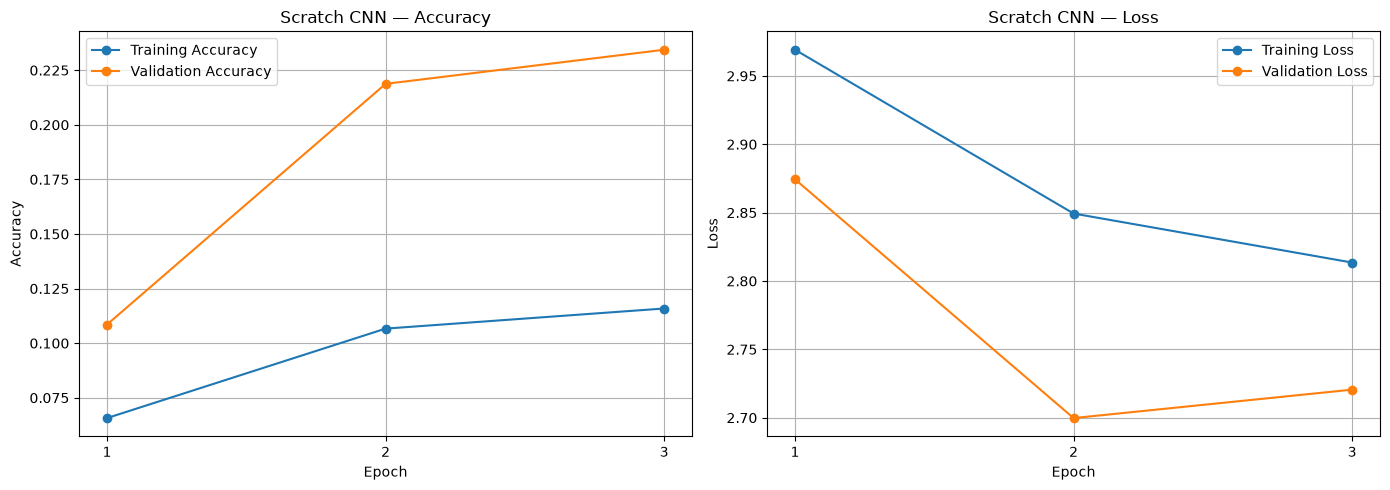

Scratch CNN plots saved: G:\AI Project ExcelR\data\Model Training dataset\outputs\scratch_cnn_learning_curves.png


In [ ]:
import matplotlib.pyplot as plt

# Plot Scratch CNN performance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_baseline.history["accuracy"], marker="o", label="Training Accuracy")
axes[0].plot(history_baseline.history["val_accuracy"], marker="o", label="Validation Accuracy")
axes[0].set_title("Scratch CNN — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(range(len(history_baseline.history["accuracy"])))
axes[0].set_xticklabels(range(1, len(history_baseline.history["accuracy"]) + 1))
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_baseline.history["loss"], marker="o", label="Training Loss")
axes[1].plot(history_baseline.history["val_loss"], marker="o", label="Validation Loss")
axes[1].set_title("Scratch CNN — Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(range(len(history_baseline.history["loss"])))
axes[1].set_xticklabels(range(1, len(history_baseline.history["loss"]) + 1))
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

scratch_plot_path = os.path.join(OUTPUT_DIR, "scratch_cnn_learning_curves.png")
plt.savefig(scratch_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Scratch CNN plots saved:", scratch_plot_path)

**Observations — Scratch CNN Learning Curves**

- Training accuracy increased across the three epochs, reaching approximately 11.6%.
- Validation accuracy improved to approximately 23.4%.
- Training loss decreased consistently, indicating progress in learning the training data.
- Validation loss decreased during the first two epochs but increased slightly in the third epoch.
- Overall performance remained limited, suggesting that the Scratch CNN learned only a modest amount of useful information during this short training run.

**Conclusion:** The Scratch CNN provides a useful baseline for comparison. Its limited performance highlights the potential advantage of using a pretrained model for food image classification.

**Limitation:** Since the model was trained for only three epochs, these results should not be treated as its maximum achievable performance.

#### Task 15 — Step 3
Now we'll generate and save the MobileNetV2 learning curves using history_mobilenet.

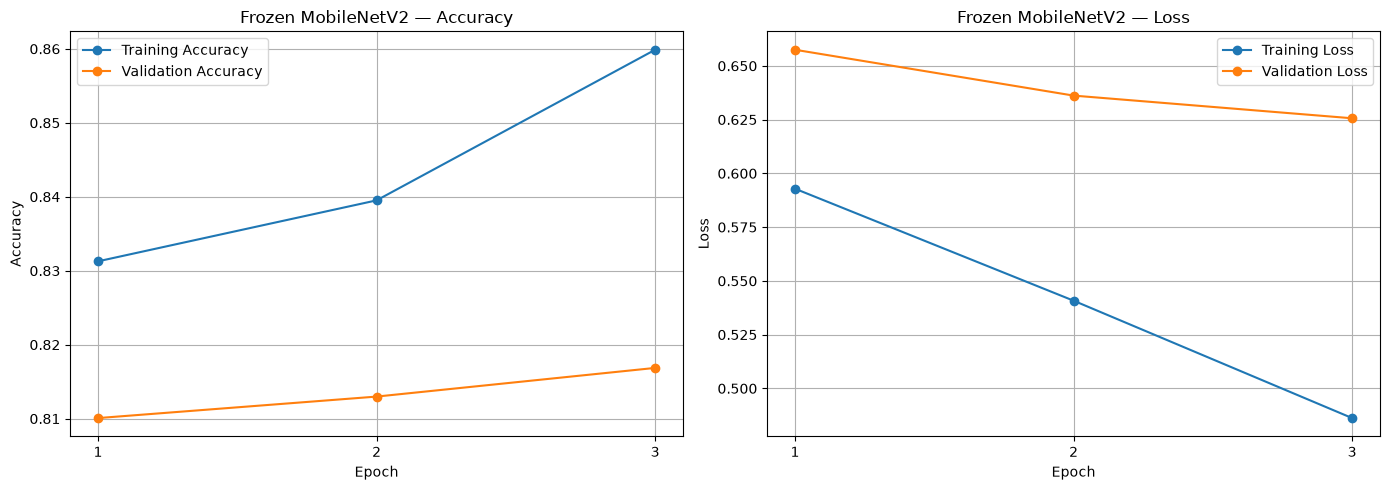

MobileNetV2 plots saved: G:\AI Project ExcelR\data\Model Training dataset\outputs\mobilenetv2_frozen_learning_curves.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MobileNetV2 accuracy
axes[0].plot(
    history_mobilenet.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)
axes[0].plot(
    history_mobilenet.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)
axes[0].set_title("Frozen MobileNetV2 — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(range(len(history_mobilenet.history["accuracy"])))
axes[0].set_xticklabels(range(1, len(history_mobilenet.history["accuracy"]) + 1))
axes[0].legend()
axes[0].grid(True)

# MobileNetV2 loss
axes[1].plot(
    history_mobilenet.history["loss"],
    marker="o",
    label="Training Loss"
)
axes[1].plot(
    history_mobilenet.history["val_loss"],
    marker="o",
    label="Validation Loss"
)
axes[1].set_title("Frozen MobileNetV2 — Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(range(len(history_mobilenet.history["loss"])))
axes[1].set_xticklabels(range(1, len(history_mobilenet.history["loss"]) + 1))
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

mobilenet_plot_path = os.path.join(
    OUTPUT_DIR, "mobilenetv2_frozen_learning_curves.png"
)
plt.savefig(mobilenet_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("MobileNetV2 plots saved:", mobilenet_plot_path)

**Observations — Frozen MobileNetV2 Learning Curves**

- Training accuracy increased from approximately 83.13% to 85.99%.
- Validation accuracy improved from approximately 81.01% to 81.69%.
- Training loss decreased consistently across all three epochs.
- Validation loss also decreased consistently, indicating continued improvement on the validation dataset.
- The training accuracy remained higher than validation accuracy, showing a modest generalisation gap.

**Conclusion:** Frozen MobileNetV2 demonstrated strong initial performance and continued improvement over the three epochs. Its pretrained image features provide a substantial advantage over the Scratch CNN baseline.

**Limitation:** These results cover only three epochs. Further fine-tuning and evaluation on the separate test dataset will help assess the model more thoroughly.

#### Task 15 — Step 5: Check saved model files

In [ ]:
import os

print("Saved model files:\n")

for file_name in os.listdir(OUTPUT_DIR):
    if file_name.endswith(".keras"):
        file_path = os.path.join(OUTPUT_DIR, file_name)
        size_mb = os.path.getsize(file_path) / (1024 * 1024)

        print(f"File: {file_name}")
        print(f"Size: {size_mb:.2f} MB")
        print("-" * 40)

Saved model files:

File: baseline_best.keras
Size: 9.48 MB
----------------------------------------


#### Task 15 — Step 6: Identify the saved model

In [ ]:
import zipfile
import json
import os

model_path = os.path.join(OUTPUT_DIR, "baseline_best.keras")

with zipfile.ZipFile(model_path, "r") as model_file:
    print("Files inside model archive:")
    print(model_file.namelist())

    config = json.loads(model_file.read("config.json"))

print("\nModel architecture:", config.get("class_name"))

print("\nLayers found in saved model:")
for layer in config["config"].get("layers", []):
    print(layer.get("class_name"), "-", layer.get("config", {}).get("name"))

Files inside model archive:
['metadata.json', 'config.json', 'model.weights.h5']

Model architecture: Functional

Layers found in saved model:
InputLayer - food_image
Lambda - mobilenet_preprocessing
Functional - mobilenetv2_1.00_224
GlobalAveragePooling2D - global_average_pooling
Dropout - classification_dropout
Dense - food_class_predictions


#### Task 15 — Step 7: Save MobileNetV2 with a clear filename

In [ ]:
import os

mobilenet_model_path = os.path.join(
    OUTPUT_DIR,
    "mobilenetv2_frozen.keras"
)

mobilenet_model.save(mobilenet_model_path)

print("Frozen MobileNetV2 saved to:", mobilenet_model_path)
print(
    "File size:",
    f"{os.path.getsize(mobilenet_model_path) / (1024 * 1024):.2f} MB"
)

Frozen MobileNetV2 saved to: G:\AI Project ExcelR\data\Model Training dataset\outputs\mobilenetv2_frozen.keras
File size: 9.48 MB


#### verify that the current in-memory model still produces predictions

In [ ]:
# Check that the in-memory MobileNetV2 model is ready for inference
print("Model:", mobilenet_model.name)
print("Input shape:", mobilenet_model.input_shape)
print("Output shape:", mobilenet_model.output_shape)

print("\nNumber of output classes:", mobilenet_model.output_shape[-1])

Model: mobilenetv2_indian_food_classifier
Input shape: (None, 224, 224, 3)
Output shape: (None, 20)

Number of output classes: 20


# Task 16 — Select and Verify the MobileNetV2 Checkpoint

| Step | Action | Purpose |
|---|---|---|
| 16.1 | Record the frozen model's configuration and validation metrics | Preserve the baseline |
| 16.2 | Verify the model's architecture and class count | Confirm it is the intended model |
| 16.3 | Preserve the frozen model separately | Avoid losing the comparison model |
| 16.4 | Prepare a separate model for fine-tuning | Keep the original baseline unchanged |

### Task 16 — Step 1: Record the frozen MobileNetV2 baseline.

Before fine-tuning, we need to preserve the current model's performance so we can compare it fairly against the fine-tuned version.

1. Objective
Establish a reliable, saved version of your frozen MobileNetV2 model that we can use as a baseline for fine-tuning and future comparison.

2. Why are we doing this?
Imagine we fine-tune MobileNetV2 and its validation accuracy falls from 81.69% to 78%.

How would we know whether fine-tuning helped or harmed the model if we didn't preserve the original version and its results?

We need a reliable reference for comparison.

In [ ]:
import json
import os

# Record the frozen MobileNetV2 experiment
frozen_baseline = {
    "model_name": mobilenet_model.name,
    "architecture": "MobileNetV2",
    "input_shape": [224, 224, 3],
    "num_classes": 20,
    "validation_loss": float(mobilenet_results[0]),
    "validation_accuracy": float(mobilenet_results[1]),
    "training_epochs": len(history_mobilenet.history["loss"]),
    "status": "Frozen pretrained base"
}

# Save the experiment record
baseline_path = os.path.join(
    OUTPUT_DIR,
    "mobilenetv2_frozen_baseline.json"
)

with open(baseline_path, "w") as file:
    json.dump(frozen_baseline, file, indent=4)

print("Frozen baseline recorded successfully.")
print(f"Validation accuracy: {mobilenet_results[1] * 100:.2f}%")
print(f"Validation loss: {mobilenet_results[0]:.4f}")
print(f"Training epochs: {len(history_mobilenet.history['loss'])}")
print(f"Configuration saved to: {baseline_path}")

Frozen baseline recorded successfully.
Validation accuracy: 81.69%
Validation loss: 0.6256
Training epochs: 3
Configuration saved to: G:\AI Project ExcelR\data\Model Training dataset\outputs\mobilenetv2_frozen_baseline.json


**Observation — Frozen MobileNetV2 Baseline**

- Recorded the model architecture, input dimensions, number of output classes, training epochs, and validation metrics.
- The model achieved a validation accuracy of **81.69%** and a validation loss of **0.6256** after three epochs.
- Saved the experiment configuration to `mobilenetv2_frozen_baseline.json` for future reference.

**Conclusion:** The frozen MobileNetV2 model now has a documented baseline against which we can compare the fine-tuned model.

**Limitation:** These metrics represent validation performance, not final performance on the held-out test dataset.

### Task 16.2 — Verify the Model Architecture

Objective

Confirm that the in-memory model has the expected MobileNetV2 architecture and a 20-class output before preparing it for fine-tuning.

Why is this important?

We want to ensure that:
- The pretrained MobileNetV2 base is present.
- The classification head produces 20 outputs.
- We know which layers will be candidates for fine-tuning.
This is a structural check; it does not train or modify the model.

In [ ]:
# Inspect the MobileNetV2 model architecture

print("Model name:", mobilenet_model.name)
print("Input shape:", mobilenet_model.input_shape)
print("Output shape:", mobilenet_model.output_shape)

# Find the pretrained MobileNetV2 base
mobilenet_base = mobilenet_model.get_layer("mobilenetv2_1.00_224")

print("\nPretrained base:", mobilenet_base.name)
print("Total layers in pretrained base:", len(mobilenet_base.layers))
print("Pretrained base trainable:", mobilenet_base.trainable)

print("\nTotal model layers:", len(mobilenet_model.layers))

Model name: mobilenetv2_indian_food_classifier
Input shape: (None, 224, 224, 3)
Output shape: (None, 20)

Pretrained base: mobilenetv2_1.00_224
Total layers in pretrained base: 154
Pretrained base trainable: False

Total model layers: 6


**Observation — MobileNetV2 Architecture Verification**

- Confirmed that the model accepts RGB images of size 224 × 224 and produces 20 output scores.
- Verified that the pretrained MobileNetV2 base, `mobilenetv2_1.00_224`, contains 154 layers.
- Confirmed that the pretrained base is currently frozen (`trainable=False`).
- The complete model contains six top-level layers, including the classification head.

**Conclusion:** The in-memory model has the expected structure for transfer learning and is ready for the next preparation step.

**Next step:** Preserve the frozen model and prepare a separate fine-tuning version without losing the original baseline.

#### Task 16.3 — Inspect the Preprocessing Layer
Objective

Task 16.3 — Inspect the model's preprocessing and architecture
Objective: Identify the serialization issue and gather the information needed to make the model reusable for fine-tuning and deployment.

What this cell does:
1. Checks the model's input and output shapes.
2. Inspects the preprocessing layer.
3. Checks the MobileNetV2 base and its trainable status.
4. Checks the existing saved model files.
5. Prints a summary of the model architecture.

In [ ]:
import os
import keras

# 1. Inspect the current model
print("=" * 60)
print("1. MODEL OVERVIEW")
print("=" * 60)

print("Model name:", mobilenet_model.name)
print("Input shape:", mobilenet_model.input_shape)
print("Output shape:", mobilenet_model.output_shape)

# 2. Inspect preprocessing
print("\n" + "=" * 60)
print("2. PREPROCESSING LAYER")
print("=" * 60)

preprocessing_layer = mobilenet_model.get_layer(
    "mobilenet_preprocessing"
)

print("Layer name:", preprocessing_layer.name)
print("Layer type:", type(preprocessing_layer).__name__)
print("Output shape:", preprocessing_layer.output.shape)
print("Configuration:")
print(preprocessing_layer.get_config())

# 3. Inspect the pretrained base
print("\n" + "=" * 60)
print("3. PRETRAINED MOBILENETV2 BASE")
print("=" * 60)

mobilenet_base = mobilenet_model.get_layer(
    "mobilenetv2_1.00_224"
)

print("Base name:", mobilenet_base.name)
print("Number of layers:", len(mobilenet_base.layers))
print("Trainable:", mobilenet_base.trainable)

# 4. Inspect saved model files
print("\n" + "=" * 60)
print("4. SAVED MODEL FILES")
print("=" * 60)

for filename in os.listdir(OUTPUT_DIR):
    if filename.endswith(".keras"):
        filepath = os.path.join(OUTPUT_DIR, filename)
        size_mb = os.path.getsize(filepath) / (1024 * 1024)
        print(f"{filename}: {size_mb:.2f} MB")

# 5. Summarise the architecture
print("\n" + "=" * 60)
print("5. MODEL ARCHITECTURE")
print("=" * 60)

mobilenet_model.summary()

1. MODEL OVERVIEW
Model name: mobilenetv2_indian_food_classifier
Input shape: (None, 224, 224, 3)
Output shape: (None, 20)

2. PREPROCESSING LAYER
Layer name: mobilenet_preprocessing
Layer type: Lambda
Output shape: (None, 224, 224, 3)
Configuration:
{'name': 'mobilenet_preprocessing', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'function': {'class_name': '__lambda__', 'config': {'code': '4wEAAAAAAAAAAAAAAAMAAAADAAAA80oAAACXAHQAAAAAAAAAAAAAAGoBAAAAAAAAAABqAgAAAAAA\nAAAAoAMAAAAAAAAAAAAAAAAAAAAAAAAAAHwApgEAAKsBAAAAAAAAAABTACkBTikE2gVrZXJhc9oM\nYXBwbGljYXRpb25z2gxtb2JpbGVuZXRfdjLaEHByZXByb2Nlc3NfaW5wdXQpAdoGaW1hZ2VzcwEA\nAAAg+j9DOi9Vc2Vycy9MRU5PVk8vQXBwRGF0YS9Mb2NhbC9UZW1wL2lweWtlcm5lbF8yMzcxMi8y\nOTc1NjgxMjQucHn6CDxsYW1iZGE+cggAAAAHAAAAcxoAAACAAJU11BMl1BMy1xND0hNDwEbRE0vU\nE0uAAPMAAAAA\n', 'defaults': None, 'closure': None}}, 'arguments': {}}

3. PRETRAINED MOBILENETV2 BASE
Base name: mobilenetv2_1.

Model: "mobilenetv2_indian_food_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ food_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 224, 224, 3)    │             0 │
│ (Lambda)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_dropout          │ (None, 1280)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ food_class_predictions (Dense)  │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,334,846 (8.91 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 51,242 (200.17 KB)

## Observation — Task 16.3: Inspect the Preprocessing Layer

- Inspected the MobileNetV2 model's input and output shapes, preprocessing layer, and pretrained base.
- Confirmed that the model accepts images of shape **224 × 224 × 3** and produces predictions for **20 food classes**.
- Identified a `Lambda` layer named `mobilenet_preprocessing`, which applies MobileNetV2's `preprocess_input` function to the input images.
- Verified that the pretrained MobileNetV2 base contains **154 layers** and is currently frozen (`trainable=False`).
- Confirmed that the model includes global average pooling, dropout, and a dense classification layer.
- Inspected the saved model files and confirmed that both `baseline_best.keras` and `mobilenetv2_frozen.keras` exist.

**Conclusion:** The model architecture and preprocessing configuration are as expected. However, the `Lambda` preprocessing layer causes a model-loading issue with Keras serialization. This needs to be resolved before reliably reloading the model for deployment.

## Observation — Task 16.4: Serialization-Compatible Preprocessing

- Created a new MobileNetV2 model using a Keras `Rescaling` layer instead of the original `Lambda` preprocessing layer.
- Replaced `mobilenet_v2.preprocess_input` with the mathematically equivalent transformation:

  `pixel_value / 127.5 - 1.0`

- This transformation converts image pixel values from the **[0, 255]** range to **[-1, 1]**, as required by MobileNetV2.
- Reused the existing pretrained base, pooling layer, dropout layer, and classification layer to preserve the trained model components.
- Kept the pretrained MobileNetV2 base frozen.
- Retained the original model so the new model can be compared against it before saving or using it for fine-tuning.

**Conclusion:** The new model is designed to use a standard Keras preprocessing layer that is more suitable for serialization and deployment. Its prediction equivalence with the original model and successful save-and-reload behavior must be verified before considering this task complete.

#### Step 1 — Build the serialization-friendly model

In [ ]:
import os
import keras
from keras import layers

# Preserve the existing trained model
old_model = mobilenet_model

# Retrieve existing components
old_base = old_model.get_layer("mobilenetv2_1.00_224")
old_pooling = old_model.get_layer("global_average_pooling")
old_dropout = old_model.get_layer("classification_dropout")
old_classifier = old_model.get_layer("food_class_predictions")

# Create a new model with serializable preprocessing
inputs = keras.Input(shape=(224, 224, 3), name="food_image")

x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1.0,
    name="mobilenet_preprocessing"
)(inputs)

x = old_base(x, training=False)
x = old_pooling(x)
x = old_dropout(x)
outputs = old_classifier(x)

mobilenet_model_serializable = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="mobilenetv2_indian_food_classifier"
)

# Preserve the frozen pretrained base
old_base.trainable = False

# Confirm the model configuration
print("New model created.")
print("Input shape:", mobilenet_model_serializable.input_shape)
print("Output shape:", mobilenet_model_serializable.output_shape)
print("Preprocessing layer:",
      type(mobilenet_model_serializable.get_layer(
          "mobilenet_preprocessing"
      )).__name__)
print("Pretrained base trainable:", old_base.trainable)

New model created.
Input shape: (None, 224, 224, 3)
Output shape: (None, 20)
Preprocessing layer: Rescaling
Pretrained base trainable: False


| Task | Activity | Purpose |
|---|---|---|
| **16.5** | Verify prediction equivalence | Ensure the new model behaves like the original. |
| **16.6** | Save and reload the model | Confirm the serialization issue is resolved. |
| **16.7** | Verify the reloaded model | Ensure predictions remain consistent after reloading. |
| **16.8** | Save model configuration and class mapping | Preserve the information needed for future inference. |
| **17** | Fine-tune MobileNetV2 | Unfreeze selected pretrained layers and train carefully. |
| **18** | Compare frozen vs fine-tuned models | Determine whether fine-tuning improves performance. |
| **19** | Evaluate the selected model on test data | Measure final performance on unseen images. |
| **20** | Prepare deployment | Build a simple interface to upload an image and predict its food class. |

#### Task 16.5 — Verify Prediction Equivalence
Objective: Confirm that replacing the preprocessing layer has not changed the model's predictions.

Why this matters: We reused the trained model components, so we want to verify that the new preprocessing produces equivalent results before using the model for fine-tuning or deployment.

In [ ]:
import numpy as np

# Get one batch of validation images
x_batch, y_batch = next(mobilenet_validation_generator)

# Generate predictions using both models
original_predictions = mobilenet_model(
    x_batch, training=False
).numpy()

new_predictions = mobilenet_model_serializable(
    x_batch, training=False
).numpy()

# Compare predictions
max_difference = np.max(
    np.abs(original_predictions - new_predictions)
)

predictions_match = np.allclose(
    original_predictions,
    new_predictions,
    atol=1e-5
)

print("Maximum absolute prediction difference:", max_difference)
print("Predictions equivalent:", predictions_match)

Maximum absolute prediction difference: 1.013279e-06
Predictions equivalent: True


Task 16.6 — Save and Reload the Model
Objective: Save the new model and confirm that Keras can reload it without the previous Lambda serialization error.

Why this matters: A model that works only in the current notebook session is not sufficient for deployment. We need to save it and load it again successfully.

In [33]:
import os
import keras

# Define a separate path to preserve the original model files
serializable_model_path = os.path.join(
    OUTPUT_DIR,
    "mobilenetv2_frozen_serializable.keras"
)

# Save the new model
mobilenet_model_serializable.save(serializable_model_path)

print("Model saved successfully.")
print("Saved path:", serializable_model_path)

# Reload using standard safe loading
reloaded_model = keras.models.load_model(
    serializable_model_path,
    compile=False
)

print("\nModel reloaded successfully.")
print("Input shape:", reloaded_model.input_shape)
print("Output shape:", reloaded_model.output_shape)
print(
    "Preprocessing layer:",
    type(reloaded_model.get_layer("mobilenet_preprocessing")).__name__
)

NameError: name 'mobilenet_model_serializable' is not defined

#### Task 16.7 — Verify the Reloaded Model
Objective: Confirm that saving and reloading the model has not changed its predictions.

Why this matters: Successful loading confirms that the file is readable, but comparing predictions verifies that the saved model retains its trained behavior.

In [ ]:
import numpy as np

# Generate predictions from the original and reloaded models
original_predictions = mobilenet_model(
    x_batch, training=False
).numpy()

reloaded_predictions = reloaded_model(
    x_batch, training=False
).numpy()

# Compare the predictions
max_difference = np.max(
    np.abs(original_predictions - reloaded_predictions)
)

predictions_match = np.allclose(
    original_predictions,
    reloaded_predictions,
    atol=1e-5
)

print("Maximum absolute prediction difference:", max_difference)
print("Predictions match after reload:", predictions_match)

Maximum absolute prediction difference: 1.013279e-06
Predictions match after reload: True


## Observation — Task 16.7: Verify the Reloaded Model

- Compared predictions from the original in-memory MobileNetV2 model with predictions from the saved and reloaded model.
- The maximum absolute prediction difference was approximately **1.013279 × 10⁻⁶**.
- `np.allclose()` returned `True` with an absolute tolerance of `1e-5`.
- Confirmed that saving and reloading preserved the model's predictions to a high degree of numerical precision on the validation batch tested.

**Conclusion:** The serialization-compatible model was saved and reloaded successfully, without changing its predictions meaningfully. It is ready for the remaining configuration checks before fine-tuning.

Task 16.8 — Save the Class Mapping and Model Configuration
Objective: Preserve the model's class mapping and essential configuration so that future predictions can be translated into the correct food labels.

Why this matters: A model outputs scores for 20 classes. Without the exact class-to-index mapping used during training, the predicted index could be associated with the wrong food label.

In [ ]:
# Inspect existing variables that may contain the class mapping
for name in [
    "class_names",
    "class_to_index",
    "index_to_class",
    "label2id",
    "id2label",
    "class_mapping",
    "label_mapping"
]:
    if name in globals():
        print(f"{name}: {type(globals()[name]).__name__}")

class_names: list


#### Task 16.8 — Save Class Mapping and Model Configuration
Objective: Save the 20 food-class labels alongside the model configuration so that predictions can be translated into the correct food names during deployment.

Why this matters: The model predicts a class index. The saved mapping ensures that each index corresponds to the same food label used during training.

In [ ]:
import os
import json

# 1. Save the existing class names without changing their order
class_mapping_path = os.path.join(
    OUTPUT_DIR,
    "class_names.json"
)

with open(class_mapping_path, "w", encoding="utf-8") as f:
    json.dump(
        class_names,
        f,
        indent=4,
        ensure_ascii=False
    )

# 2. Save the model configuration
model_config = {
    "model_name": "mobilenetv2_indian_food_classifier",
    "architecture": "MobileNetV2",
    "input_shape": [224, 224, 3],
    "num_classes": len(class_names),
    "preprocessing": "Rescaling: pixel / 127.5 - 1.0",
    "pretrained_base_trainable": False,
    "training_epochs": 3,
    "model_file": "mobilenetv2_frozen_serializable.keras",
    "class_mapping_file": "class_names.json"
}

config_path = os.path.join(
    OUTPUT_DIR,
    "mobilenetv2_frozen_config.json"
)

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(
        model_config,
        f,
        indent=4
    )

# 3. Verify the saved files
print("Class mapping saved:", class_mapping_path)
print("Model configuration saved:", config_path)
print("Number of classes:", len(class_names))
print("First five class names:", class_names[:5])

Class mapping saved: G:\AI Project ExcelR\data\Model Training dataset\outputs\class_names.json
Model configuration saved: G:\AI Project ExcelR\data\Model Training dataset\outputs\mobilenetv2_frozen_config.json
Number of classes: 20
First five class names: ['burger', 'butter_naan', 'chai', 'chapati', 'chole_bhature']


## Observation — Task 16.8: Save Class Mapping and Model Configuration

- Saved the existing 20 food-class labels to `class_names.json`, preserving their original order.
- Saved the model configuration to `mobilenetv2_frozen_config.json`.
- Recorded the model architecture, input shape, number of classes, preprocessing method, frozen-base status, training epochs, and associated filenames.
- Confirmed that both configuration files were saved in the project output directory.

**Conclusion:** The frozen MobileNetV2 model now has a saved class-label list and configuration file to support reproducibility and future deployment.

### Task 17 — Fine-Tuning MobileNetV2: 5 parts

| Part | Activity | Purpose |
|---|---|---|
| **17.1** | Inspect MobileNetV2 layers | Understand the network before unfreezing layers. |
| **17.2** | Select and unfreeze layers | Allow selected pretrained layers to learn from Indian food images. |
| **17.3** | Recompile the model | Use a low learning rate to protect previously learned features. |
| **17.4** | Train the fine-tuned model | Train for a small number of epochs and monitor validation performance. |
| **17.5** | Evaluate and save the model | Compare it with the frozen baseline and save the fine-tuned model if appropriate. |

| Parameter | Frozen MobileNetV2 (Baseline) | Fine-Tuned MobileNetV2 |
|---|---|---|
| Architecture | MobileNetV2 + classification head | MobileNetV2 + classification head |
| Input image size | 224 × 224 × 3 | 224 × 224 × 3 |
| Number of classes | 20 | 20 |
| Pretrained weights | ImageNet | ImageNet, further adapted to your dataset |
| Pretrained base | Frozen | Partially unfrozen |
| Total layers in pretrained base | 154 | 154 |
| Trainable layers in pretrained base | 0 | 20 marked trainable |
| Batch Normalization layers | Frozen | Frozen |
| Optimizer | Adam | Adam |
| Learning rate | Not yet verified from the saved baseline configuration | `0.00001` (`1e-5`) |
| Loss function | Sparse categorical cross-entropy | Sparse categorical cross-entropy |
| Metric | Accuracy | Accuracy |
| Training epochs | 3 | 3 planned |
| Best-checkpoint monitoring | Validation loss | Validation loss |
| Model file | `mobilenetv2_frozen_serializable.keras` | `mobilenetv2_finetuned_best.keras` |
| Validation accuracy | **81.69%** | Pending evaluation |
| Validation loss | **0.6256** | Pending evaluation |

In [36]:
# Task 17 — Restore generators after restarting VS Code

import numpy as np

# Recreate the training generator
mobilenet_train_generator = mobilenet_data_generator(
    train_path,
    batch_size=BATCH_SIZE,
    shuffle=True,
    augment=True
)

# Recreate the validation generator
mobilenet_validation_generator = mobilenet_data_generator(
    validation_path,
    batch_size=BATCH_SIZE,
    shuffle=False,
    augment=False
)

# Restore step counts
train_steps = int(np.ceil(4125 / BATCH_SIZE))
validation_steps = int(np.ceil(1032 / BATCH_SIZE))

print("Batch size:", BATCH_SIZE)
print("Training samples:", 4125)
print("Training steps per epoch:", train_steps)
print("Validation samples:", 1032)
print("Validation steps:", validation_steps)

print("\nGenerators restored successfully.")

Batch size: 32
Training samples: 4125
Training steps per epoch: 129
Validation samples: 1032
Validation steps: 33

Generators restored successfully.


#### Task 17.1 — Prepare MobileNetV2 for Fine-Tuning
Objective: Identify the final layers of the pretrained MobileNetV2 network before deciding which layers to unfreeze.

Why are we doing this?

So far, we have trained the classification head while keeping the pretrained MobileNetV2 base frozen. Fine-tuning allows selected pretrained layers to adapt their learned image features to Indian food images.

We should not unfreeze the entire network immediately. With your dataset and limited training time, we'll start by examining the final layers and then select a small group for fine-tuning.

In [27]:
# Retrieve the pretrained MobileNetV2 base
mobilenet_base = reloaded_model.get_layer("mobilenetv2_1.00_224")

print("Pretrained base:", mobilenet_base.name)
print("Total layers:", len(mobilenet_base.layers))
print("Currently trainable:", mobilenet_base.trainable)

print("\nLast 25 layers of MobileNetV2:")
print("-" * 75)

for layer in mobilenet_base.layers[-25:]:
    print(
        f"Name: {layer.name:<35} "
        f"Type: {type(layer).__name__:<25} "
        f"Trainable: {layer.trainable}"
    )

Pretrained base: mobilenetv2_1.00_224
Total layers: 154
Currently trainable: False

Last 25 layers of MobileNetV2:
---------------------------------------------------------------------------
Name: block_14_depthwise_BN               Type: BatchNormalization        Trainable: False
Name: block_14_depthwise_relu             Type: ReLU                      Trainable: False
Name: block_14_project                    Type: Conv2D                    Trainable: False
Name: block_14_project_BN                 Type: BatchNormalization        Trainable: False
Name: block_14_add                        Type: Add                       Trainable: False
Name: block_15_expand                     Type: Conv2D                    Trainable: False
Name: block_15_expand_BN                  Type: BatchNormalization        Trainable: False
Name: block_15_expand_relu                Type: ReLU                      Trainable: False
Name: block_15_depthwise                  Type: DepthwiseConv2D           Trainab

### 

#### Task 17.2 — Select and Unfreeze Layers
Objective: Allow the final few convolutional blocks to adapt their learned features to Indian food images while preserving the earlier pretrained features.

Our approach: Unfreeze the last 30 layers, but keep Batch Normalization layers frozen. This is a reasonable starting point for fine-tuning with a relatively small dataset.

In [37]:
# Keep the entire base frozen initially
mobilenet_base.trainable = False

# Unfreeze the last 30 layers, except Batch Normalization layers
for layer in mobilenet_base.layers[-30:]:
    if not isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = True

# Verify the changes
trainable_layers = [
    layer.name
    for layer in mobilenet_base.layers
    if layer.trainable
]

print("Total layers:", len(mobilenet_base.layers))
print("Trainable layers:", len(trainable_layers))
print("First 10 trainable layers:", trainable_layers[:10])
print("Last 10 trainable layers:", trainable_layers[-10:])

print(
    "Trainable Batch Normalization layers:",
    sum(
        isinstance(layer, keras.layers.BatchNormalization)
        and layer.trainable
        for layer in mobilenet_base.layers
    )
)

Total layers: 154
Trainable layers: 20
First 10 trainable layers: ['input_layer_2', 'block_14_expand', 'block_14_expand_relu', 'block_14_depthwise', 'block_14_depthwise_relu', 'block_14_project', 'block_14_add', 'block_15_expand', 'block_15_expand_relu', 'block_15_depthwise']
Last 10 trainable layers: ['block_15_depthwise_relu', 'block_15_project', 'block_15_add', 'block_16_expand', 'block_16_expand_relu', 'block_16_depthwise', 'block_16_depthwise_relu', 'block_16_project', 'Conv_1', 'out_relu']
Trainable Batch Normalization layers: 0


### Task 17.3 — Recompile the Model
Objective: Configure the model for fine-tuning with a low learning rate.

Why this matters: Fine-tuning updates pretrained weights, so a high learning rate could damage useful features learned during initial training. We'll use 1e-5 and keep the Batch Normalization layers frozen.

In [38]:
import keras

# Recompile after changing layer trainability
reloaded_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled successfully.")
print("Learning rate: 1e-5")
print("Loss: sparse_categorical_crossentropy")
print("Metric: accuracy")
print("Trainable layers:", sum(
    layer.trainable for layer in mobilenet_base.layers
))

Model recompiled successfully.
Learning rate: 1e-5
Loss: sparse_categorical_crossentropy
Metric: accuracy
Trainable layers: 20


### Task 17.4 — Fine-Tune MobileNetV2
Objective: Train the selected layers on your Indian food dataset and determine whether fine-tuning improves validation performance over the frozen baseline.

Why this matters: The frozen model already achieved 81.69% validation accuracy. Fine-tuning may help MobileNetV2 learn features specific to your 20 food classes, but improvement is not guaranteed.

We'll train for 3 epochs to stay consistent with your existing experiment and time constraints. We'll also save the best checkpoint based on validation loss.

In [39]:
import os
import keras

# Save the best fine-tuned checkpoint separately
fine_tuned_checkpoint_path = os.path.join(
    OUTPUT_DIR,
    "mobilenetv2_finetuned_best.keras"
)

# Save the model with the lowest validation loss
checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=fine_tuned_checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Fine-tune the model
history_finetuned = reloaded_model.fit(
    mobilenet_train_generator,
    validation_data=mobilenet_validation_generator,
    epochs=3,
    callbacks=[checkpoint_callback]
)

print("\nFine-tuning completed.")
print("Best checkpoint:", fine_tuned_checkpoint_path)
print("Training epochs completed:", len(history_finetuned.history["loss"]))

g:\AI Project ExcelR\AI_proj_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/3
    436/Unknown 1004s 2s/step - accuracy: 0.8895 - loss: 0.3774

KeyboardInterrupt: 

In [40]:
# Task 17.4 — Inspect generator configuration

print("Training generator type:", type(mobilenet_train_generator))
print("Generator function:", mobilenet_train_generator.gi_code.co_name)

print("\nTraining generator state:")
print("Generator exhausted:", mobilenet_train_generator.gi_frame is None)

print("\nExpected training steps:", train_steps)
print("Expected validation steps:", validation_steps)

print("\nGenerator function source location:")
print("Filename:", mobilenet_train_generator.gi_code.co_filename)
print("First line:", mobilenet_train_generator.gi_code.co_firstlineno)

Training generator type: <class 'generator'>
Generator function: mobilenet_data_generator

Training generator state:
Generator exhausted: False

Expected training steps: 129
Expected validation steps: 33

Generator function source location:
Filename: C:\Users\LENOVO\AppData\Local\Temp\ipykernel_24424\3489097101.py
First line: 4


In [41]:
import os
import keras

fine_tuned_checkpoint_path = os.path.join(
    OUTPUT_DIR,
    "mobilenetv2_finetuned_best.keras"
)

# Save the model with the best validation loss
checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=fine_tuned_checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Stop early if validation loss does not improve
early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=1,
    restore_best_weights=True,
    verbose=1
)

history_finetuned = reloaded_model.fit(
    mobilenet_train_generator,
    steps_per_epoch=train_steps,
    validation_data=mobilenet_validation_generator,
    validation_steps=validation_steps,
    epochs=3,
    callbacks=[
        checkpoint_callback,
        early_stopping_callback
    ],
    verbose=1
)

print("\nFine-tuning completed.")
print("Epochs completed:", len(history_finetuned.history["loss"]))
print("Best checkpoint:", fine_tuned_checkpoint_path)
print("Training accuracy:", history_finetuned.history["accuracy"][-1])
print("Validation accuracy:", history_finetuned.history["val_accuracy"][-1])
print("Validation loss:", history_finetuned.history["val_loss"][-1])

g:\AI Project ExcelR\AI_proj_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/3
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9118 - loss: 0.3020
Epoch 1: val_loss improved from None to 0.57190, saving model to G:\AI Project ExcelR\data\Model Training dataset\outputs\mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to G:\AI Project ExcelR\data\Model Training dataset\outputs\mobilenetv2_finetuned_best.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 379s 3s/step - accuracy: 0.9118 - loss: 0.3020 - val_accuracy: 0.8391 - val_loss: 0.5719
Epoch 2/3
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9081 - loss: 0.3029
Epoch 2: val_loss improved from 0.57190 to 0.56998, saving model to G:\AI Project ExcelR\data\Model Training dataset\outputs\mobilenetv2_finetuned_best.keras

Epoch 2: finished saving model to G:\AI Project ExcelR\data\Model Training dataset\outputs\mobilenetv2_finetuned_best.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 411s 3s/step - accuracy: 0.9081 - loss: 0.3029 - val_accuracy: 0.8440 - val_loss: 0.5700
Epoch 3/3
129/129 ━━━━━━━━━━━━━━━

| Metric | Frozen | Fine-tuned | Improvement |
|---|---:|---:|---:|
| Validation accuracy | 81.69% | 84.40% | **+2.71 percentage points** |
| Validation loss | 0.62562 | 0.56998 | **0.05564 lower** |

# Compare:
- Scratch CNN
- Frozen MobileNetV2
- Fine-tuned MobileNetV2

In [42]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Scratch CNN",
        "Validation Accuracy": "11.92%",
        "Validation Loss": "2.7535"
    },
    {
        "Model": "Frozen MobileNetV2",
        "Validation Accuracy": "81.69%",
        "Validation Loss": "0.6256"
    },
    {
        "Model": "Fine-tuned MobileNetV2",
        "Validation Accuracy": "84.40%",
        "Validation Loss": "0.5700"
    }
])

display(comparison)

,Model,Validation Accuracy,Validation Loss
0,Scratch CNN,11.92%,2.7535
1,Frozen MobileNetV2,81.69%,0.6256
2,Fine-tuned MobileNetV2,84.40%,0.5700


_____

## Phase 3 — Save and Verify the Final Model

We'll preserve the successful serialization approach we used for the frozen model.

#### Task 3.1 — Save the selected model
Objective: Save the fine-tuned model as a standalone .keras file.

In [43]:
import os
import keras

FINAL_MODEL_PATH = os.path.join(
    OUTPUT_DIR,
    "indian_food_classifier_final.keras"
)

# Load the best fine-tuned checkpoint
finetuned_model = keras.models.load_model(
    os.path.join(OUTPUT_DIR, "mobilenetv2_finetuned_best.keras"),
    compile=False
)

# Save the selected model under its final deployment filename
finetuned_model.save(FINAL_MODEL_PATH)

print("Final model saved successfully.")
print("Path:", FINAL_MODEL_PATH)
print("Input shape:", finetuned_model.input_shape)
print("Output shape:", finetuned_model.output_shape)
print("Number of classes:", len(class_names))

Final model saved successfully.
Path: G:\AI Project ExcelR\data\Model Training dataset\outputs\indian_food_classifier_final.keras
Input shape: (None, 224, 224, 3)
Output shape: (None, 20)
Number of classes: 20


#### Observation — Task 3.1: Save the Selected Model**

- Loaded the best fine-tuned MobileNetV2 checkpoint, `mobilenetv2_finetuned_best.keras`.
- Saved the selected model in `.keras` format as `indian_food_classifier_final.keras`.
- Confirmed that the model accepts input images of shape **224 × 224 × 3**.
- Verified that the model produces predictions for **20 food classes**.
- Saved the final model successfully in the project output directory.

**Conclusion:** The fine-tuned MobileNetV2 model has been saved as the final deployment model. The next steps are to preserve the class mapping and model configuration, reload the saved model, and verify its predictions on a sample image.

### Phase 3 — Task 3.2: Preserve class_names.json
1. Objective — What are we trying to achieve?
Our model can classify images into 20 Indian food classes, but its output consists of numerical scores rather than food names.

2. Why is this step necessary?
When we deploy our model, the application will load the saved model independently of the training notebook.

The application needs two things:
- The trained model: Predicts scores for the 20 food classes.
- class_names.json: Tells the application which food label corresponds to each output position.
Without the correct mapping, the model might predict the correct output position but display the wrong food name.

In [44]:
import os
import json

CLASS_NAMES_PATH = os.path.join(
    OUTPUT_DIR,
    "class_names.json"
)

# Save the mapping only if the file does not already exist
if not os.path.exists(CLASS_NAMES_PATH):
    with open(CLASS_NAMES_PATH, "w", encoding="utf-8") as f:
        json.dump(class_names, f, indent=4)

# Load the saved mapping
with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as f:
    saved_class_names = json.load(f)

# Verify the mapping
print("Mapping file:", CLASS_NAMES_PATH)
print("Number of classes:", len(saved_class_names))
print("First five classes:", saved_class_names[:5])
print(
    "Mapping matches current class order:",
    saved_class_names == class_names
)

Mapping file: G:\AI Project ExcelR\data\Model Training dataset\outputs\class_names.json
Number of classes: 20
First five classes: ['burger', 'butter_naan', 'chai', 'chapati', 'chole_bhature']
Mapping matches current class order: True


**Observation — Task 3.2: Preserve `class_names.json`**

- Verified the class mapping file at `outputs/class_names.json`.
- Confirmed that the file contains **20 food classes**.
- Checked the first five labels: `burger`, `butter_naan`, `chai`, `chapati`, and `chole_bhature`.
- Compared the saved mapping with the current `class_names` list and confirmed that the class order matches.
- Preserved the existing mapping without overwriting it.

**Conclusion:** The class mapping is available and matches the current class order. This file will allow the deployed application to convert the model's numerical output positions into the correct food labels.

#### Phase 3 — Task 3.3: Preserve the Model Configuration
1. Objective — What are we trying to achieve?
We have saved our selected fine-tuned MobileNetV2 model as indian_food_classifier_final.keras and verified that class_names.json contains the correct 20 food labels.

Now we need to preserve the model configuration so that we can understand how the model was built and how it should be used during deployment.

The configuration acts as a reference document describing the model's important settings.

2. Why is this step necessary?
When we deploy the model, we should not have to depend on our training notebook to remember its settings.

The configuration will record details such as:
- Model architecture: MobileNetV2.
- Input image size: 224 × 224 × 3.
- Number of classes: 20.
- Preprocessing: Pixel values are rescaled from [0, 255] to [-1, 1] inside the model.
- Selected model file: indian_food_classifier_final.keras.
- Class mapping file: class_names.json.
- Training approach: Transfer learning followed by fine-tuning.
We will save these details in a JSON file named final_model_config.json.

In [45]:
import os
import json

FINAL_CONFIG_PATH = os.path.join(
    OUTPUT_DIR,
    "final_model_config.json"
)

final_model_config = {
    "model_name": "indian_food_classifier_final",
    "architecture": "MobileNetV2",
    "training_approach": "Transfer Learning with Fine-Tuning",
    "input_shape": [224, 224, 3],
    "num_classes": 20,
    "preprocessing": "Rescaling: pixel / 127.5 - 1.0",
    "pretrained_weights": "ImageNet",
    "fine_tuning": {
        "unfrozen_base_layers": 20,
        "batch_normalization_layers_frozen": True,
        "learning_rate": 0.00001,
        "maximum_epochs": 3,
        "best_epoch": 2
    },
    "model_file": "indian_food_classifier_final.keras",
    "class_mapping_file": "class_names.json"
}

with open(FINAL_CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(final_model_config, f, indent=4)

# Reload the configuration to verify the saved file
with open(FINAL_CONFIG_PATH, "r", encoding="utf-8") as f:
    saved_config = json.load(f)

print("Configuration saved successfully.")
print("Configuration path:", FINAL_CONFIG_PATH)
print("Architecture:", saved_config["architecture"])
print("Input shape:", saved_config["input_shape"])
print("Number of classes:", saved_config["num_classes"])
print("Model file:", saved_config["model_file"])
print("Class mapping file:", saved_config["class_mapping_file"])

Configuration saved successfully.
Configuration path: G:\AI Project ExcelR\data\Model Training dataset\outputs\final_model_config.json
Architecture: MobileNetV2
Input shape: [224, 224, 3]
Number of classes: 20
Model file: indian_food_classifier_final.keras
Class mapping file: class_names.json


#### Observation — Task 3.3: Preserve the Model Configuration

- Created and saved `final_model_config.json` in the project output directory.
- Recorded the model architecture as **MobileNetV2** with an input shape of **224 × 224 × 3**.
- Confirmed that the model supports **20 food classes**.
- Documented the preprocessing method, fine-tuning settings, and training configuration.
- Recorded the final model filename as `indian_food_classifier_final.keras`.
- Recorded the class mapping filename as `class_names.json`.
- Reloaded the configuration file and verified that the key settings were saved correctly.

**Conclusion:** The model configuration has been saved successfully. It provides a reference for the model's architecture, preprocessing, training settings, and associated files during deployment.

### Next: Task 3.4 — Reload the Selected Model
Objective: Verify that the final model can be loaded from its saved .keras file without relying on the model object remaining in memory from training.

Our selected model is **Fine-tuned MobileNetV2**.

### Model files in our output directory

- **Selected model:** `indian_food_classifier_final.keras`
- Fine-tuned checkpoint: `mobilenetv2_finetuned_best.keras`
- Frozen baseline: `mobilenetv2_frozen_serializable.keras`
- Class mapping: `class_names.json`
- Configuration: `final_model_config.json`

In [46]:
import os
import keras

FINAL_MODEL_PATH = os.path.join(
    OUTPUT_DIR,
    "indian_food_classifier_final.keras"
)

reloaded_final_model = keras.models.load_model(
    FINAL_MODEL_PATH,
    compile=False
)

print("Final model reloaded successfully.")
print("Input shape:", reloaded_final_model.input_shape)
print("Output shape:", reloaded_final_model.output_shape)
print("Number of classes:", reloaded_final_model.output_shape[-1])

Final model reloaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 20)
Number of classes: 20


#### Observation — Task 3.4: Reload the Selected Model

- Reloaded `indian_food_classifier_final.keras` successfully using Keras with `compile=False`.
- Verified that the model accepts input images of shape **224 × 224 × 3**.
- Confirmed that the model output shape is `(None, 20)`, corresponding to **20 food classes**.
- Verified that the saved model can be loaded independently of the original training session.

**Conclusion:** The final fine-tuned MobileNetV2 model was reloaded successfully, and its input and output dimensions match the expected configuration. It is ready for sample-image prediction testing.

### Next: Task 3.5 — Run a Sample Image Through the Reloaded Model
Objective: Confirm that the reloaded model can process an actual food image and generate predictions.

We'll select one image from the existing test dataset, pass it through the model using the expected input format, and inspect its predicted food class. Since preprocessing is already built into the model, we must not apply MobileNetV2 preprocessing a second time.

What are we going to do?
1. Select one image from the existing test dataset.
2. Decode the image and resize it to 224 × 224 pixels.
3. Pass it to reloaded_final_model.
4. Check that the model returns 20 prediction scores.

In [47]:
import numpy as np
from PIL import Image
import io

# Get one batch from the existing test-data generator
test_images, test_labels = next(
    mobilenet_data_generator(
        test_path,
        batch_size=1,
        shuffle=False,
        augment=False
    )
)

# Run prediction through the reloaded final model
predictions = reloaded_final_model.predict(
    test_images,
    verbose=0
)

print("Sample prediction completed successfully.")
print("Input batch shape:", test_images.shape)
print("Prediction output shape:", predictions.shape)
print("Actual class index:", int(test_labels[0]))
print("Predicted class index:", int(np.argmax(predictions[0])))
print("Number of prediction scores:", len(predictions[0]))

Sample prediction completed successfully.
Input batch shape: (1, 224, 224, 3)
Prediction output shape: (1, 20)
Actual class index: 16
Predicted class index: 16
Number of prediction scores: 20


In [48]:
import numpy as np
from sklearn.metrics import accuracy_score
from collections import Counter

# Load the complete test dataset without augmentation or shuffling
test_generator = mobilenet_data_generator(
    test_path,
    batch_size=32,
    shuffle=False,
    augment=False
)

all_true_labels = []
all_predictions = []

# Calculate the number of test batches
test_steps = int(np.ceil(941 / 32))

# Predict each batch
for _ in range(test_steps):
    images, labels = next(test_generator)

    probabilities = reloaded_final_model.predict(
        images,
        verbose=0
    )

    all_predictions.append(probabilities)
    all_true_labels.append(labels)

# Combine all batches
y_prob = np.concatenate(all_predictions, axis=0)
y_true = np.concatenate(all_true_labels, axis=0)

# Handle integer labels or one-hot encoded labels
if y_true.ndim > 1:
    y_true = np.argmax(y_true, axis=1)

y_true = y_true.astype(int)

# Keep only the actual test samples
y_prob = y_prob[:len(y_true)]
y_true = y_true[:len(y_prob)]

# Top-1 predictions
top1_indices = np.argmax(y_prob, axis=1)
top1_accuracy = accuracy_score(y_true, top1_indices)

# Top-3 predictions
top3_indices = np.argsort(y_prob, axis=1)[:, -3:]
top3_accuracy = np.mean(
    [true_label in predicted_indices
     for true_label, predicted_indices in zip(y_true, top3_indices)]
)

print("FINAL MODEL — TEST SET EVALUATION")
print("-" * 45)
print("Test images evaluated:", len(y_true))
print(f"Top-1 Accuracy: {top1_accuracy:.2%}")
print(f"Top-3 Accuracy: {top3_accuracy:.2%}")

# Show sample predictions
print("\nSAMPLE PREDICTIONS")
print("-" * 45)

for i in range(min(10, len(y_true))):
    predicted_index = int(top1_indices[i])
    actual_index = int(y_true[i])

    top_three = np.argsort(y_prob[i])[::-1][:3]

    print(f"\nImage {i + 1}")
    print("Actual label:   ", class_names[actual_index])
    print("Predicted label:", class_names[predicted_index])
    print(f"Confidence:      {y_prob[i][predicted_index]:.2%}")
    print("Top 3 predictions:")

    for index in top_three:
        print(f"  {class_names[index]}: {y_prob[i][index]:.2%}")

FINAL MODEL — TEST SET EVALUATION
---------------------------------------------
Test images evaluated: 941
Top-1 Accuracy: 82.57%
Top-3 Accuracy: 93.94%

SAMPLE PREDICTIONS
---------------------------------------------

Image 1
Actual label:    pakode
Predicted label: pakode
Confidence:      97.19%
Top 3 predictions:
  pakode: 97.19%
  masala_dosa: 1.01%
  idli: 0.80%

Image 2
Actual label:    pakode
Predicted label: pakode
Confidence:      67.96%
Top 3 predictions:
  pakode: 67.96%
  fried_rice: 21.75%
  butter_naan: 3.55%

Image 3
Actual label:    dal_makhani
Predicted label: dal_makhani
Confidence:      99.95%
Top 3 predictions:
  dal_makhani: 99.95%
  kadai_paneer: 0.03%
  chai: 0.01%

Image 4
Actual label:    chole_bhature
Predicted label: kadai_paneer
Confidence:      71.30%
Top 3 predictions:
  kadai_paneer: 71.30%
  fried_rice: 17.14%
  momos: 5.77%

Image 5
Actual label:    butter_naan
Predicted label: idli
Confidence:      33.09%
Top 3 predictions:
  idli: 33.09%
  kadai_pane

#### Observation — Task 3.5: Evaluate Predictions on the Test Dataset

- Evaluated the saved fine-tuned MobileNetV2 model on all 941 test images without data augmentation.
- Achieved **82.57% Top-1 accuracy**, meaning the highest-ranked prediction matched the actual label for approximately 83% of test images.
- Achieved **93.94% Top-3 accuracy**, meaning the actual label appeared among the model's three highest-ranked predictions for approximately 94% of test images.
- Inspected 10 sample predictions and compared actual labels, predicted labels, confidence scores, and the top three predicted classes.
- Observed both correct and incorrect predictions. For example, the model correctly classified `pakode`, `dal_makhani`, and `chapati` in several samples, but misclassified some `chole_bhature`, `butter_naan`, and `pakode` images.
- Some incorrect predictions had high confidence, indicating that confidence alone does not guarantee a correct classification.

**Conclusion:** The final model demonstrates promising classification performance on the test dataset. Top-3 accuracy is higher than Top-1 accuracy, showing that the correct class often appears among the model's leading predictions even when it is not ranked first.

### Task 3.6 — Verify the Predicted Class Labels
Objective
Verify that the numerical class indices predicted by the final model map to the correct food names using class_names.json.

Why are we doing this?

Our model produces 20 prediction scores for each image. The position of the highest score represents the predicted class index. We must ensure that this index maps to the correct food label.

For example, if the predicted index is 16, we need to verify that class_names[16] returns the correct food name.

This is important for deployment because users should see food names such as pakode rather than numerical indices.

Code cell -\
We already have y_true, y_prob, top1_indices, and class_names from Task 3.5. We'll verify the mapping without retraining the model or rerunning the test evaluation.

In [49]:
import json
import os
import numpy as np

# Load the saved class mapping
CLASS_NAMES_PATH = os.path.join(
    OUTPUT_DIR,
    "class_names.json"
)

with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as file:
    saved_class_names = json.load(file)

# Verify the saved mapping matches the mapping used during evaluation
print("Number of saved classes:", len(saved_class_names))
print("Number of model output classes:", reloaded_final_model.output_shape[-1])
print("Mapping matches current class order:",
      saved_class_names == class_names)

# Verify predicted indices map to valid food labels
valid_indices = (
    np.all(top1_indices >= 0)
    and np.all(top1_indices < len(saved_class_names))
)

print("All predicted indices have valid labels:", valid_indices)

# Display sample predictions using the saved mapping
print("\nSAMPLE LABEL VERIFICATION")
print("-" * 45)

for i in range(min(10, len(y_true))):
    actual_label = saved_class_names[int(y_true[i])]
    predicted_label = saved_class_names[int(top1_indices[i])]

    print(f"Image {i + 1}:")
    print("  Actual label:   ", actual_label)
    print("  Predicted label:", predicted_label)
    print("  Label matches:  ", actual_label == predicted_label)

Number of saved classes: 20
Number of model output classes: 20
Mapping matches current class order: True
All predicted indices have valid labels: True

SAMPLE LABEL VERIFICATION
---------------------------------------------
Image 1:
  Actual label:    pakode
  Predicted label: pakode
  Label matches:   True
Image 2:
  Actual label:    pakode
  Predicted label: pakode
  Label matches:   True
Image 3:
  Actual label:    dal_makhani
  Predicted label: dal_makhani
  Label matches:   True
Image 4:
  Actual label:    chole_bhature
  Predicted label: kadai_paneer
  Label matches:   False
Image 5:
  Actual label:    butter_naan
  Predicted label: idli
  Label matches:   False
Image 6:
  Actual label:    chapati
  Predicted label: chapati
  Label matches:   True
Image 7:
  Actual label:    butter_naan
  Predicted label: butter_naan
  Label matches:   True
Image 8:
  Actual label:    pakode
  Predicted label: jalebi
  Label matches:   False
Image 9:
  Actual label:    kulfi
  Predicted label: ku

_______

_______

# Phase 4 — Task 4.1: Verify the Application Files and Environment
Objective

Before writing the application, confirm that the model, class mapping, and Python environment are ready.
Why this matters

Our selected model is saved as indian_food_classifier_final.keras, and it already contains a Rescaling layer that converts pixel values from [0, 255] to [-1, 1].

Important: We must not apply MobileNetV2 preprocessing a second time. The application will convert uploaded images to RGB, resize them to 224 × 224, and pass pixel values to the model.

In [50]:
import os
import json

OUTPUT_DIR = r"G:\AI Project ExcelR\data\Model Training dataset\outputs"

FINAL_MODEL_PATH = os.path.join(
    OUTPUT_DIR,
    "indian_food_classifier_final.keras"
)

CLASS_NAMES_PATH = os.path.join(
    OUTPUT_DIR,
    "class_names.json"
)

CONFIG_PATH = os.path.join(
    OUTPUT_DIR,
    "final_model_config.json"
)

required_files = {
    "Final model": FINAL_MODEL_PATH,
    "Class mapping": CLASS_NAMES_PATH,
    "Model configuration": CONFIG_PATH
}

print("APPLICATION FILE CHECK")
print("-" * 40)

for name, path in required_files.items():
    print(f"{name}: {'FOUND' if os.path.isfile(path) else 'MISSING'}")
    print(f"Path: {path}\n")

if os.path.isfile(CLASS_NAMES_PATH):
    with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as file:
        app_class_names = json.load(file)

    print("Number of food classes:", len(app_class_names))
    print("First five classes:", app_class_names[:5])

APPLICATION FILE CHECK
----------------------------------------
Final model: FOUND
Path: G:\AI Project ExcelR\data\Model Training dataset\outputs\indian_food_classifier_final.keras

Class mapping: FOUND
Path: G:\AI Project ExcelR\data\Model Training dataset\outputs\class_names.json

Model configuration: FOUND
Path: G:\AI Project ExcelR\data\Model Training dataset\outputs\final_model_config.json

Number of food classes: 20
First five classes: ['burger', 'butter_naan', 'chai', 'chapati', 'chole_bhature']


### Task 4.2 — Copy the model and configuration files
Objective

Prepare the trained model and its supporting configuration files inside streamlit_app, keeping the original files unchanged.

Step 1: Copy the files\
Run the following code in a new cell in your existing notebook.

What this code does:
- Copies the trained model into streamlit_app/models/.
- Copies the class mapping and model configuration into streamlit_app/config/.
- Creates the destination folders if necessary.
- Does not modify or delete the original files.
- Verifies that the copied files exist and checks their sizes.

In [51]:
import os
import shutil

# Source files: existing project outputs
SOURCE_DIR = r"G:\AI Project ExcelR\data\Model Training dataset\outputs"

SOURCE_MODEL = os.path.join(
    SOURCE_DIR,
    "indian_food_classifier_final.keras"
)

SOURCE_CLASS_NAMES = os.path.join(
    SOURCE_DIR,
    "class_names.json"
)

SOURCE_CONFIG = os.path.join(
    SOURCE_DIR,
    "final_model_config.json"
)

# Destination folders: Streamlit deployment
APP_DIR = r"G:\AI Project ExcelR\streamlit_app"

MODELS_DIR = os.path.join(APP_DIR, "models")
CONFIG_DIR = os.path.join(APP_DIR, "config")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(CONFIG_DIR, exist_ok=True)

# Destination files
FILE_COPIES = {
    SOURCE_MODEL: os.path.join(
        MODELS_DIR,
        "indian_food_classifier_final.keras"
    ),
    SOURCE_CLASS_NAMES: os.path.join(
        CONFIG_DIR,
        "class_names.json"
    ),
    SOURCE_CONFIG: os.path.join(
        CONFIG_DIR,
        "final_model_config.json"
    )
}

print("COPYING DEPLOYMENT FILES")
print("-" * 45)

for source, destination in FILE_COPIES.items():

    if not os.path.isfile(source):
        raise FileNotFoundError(
            f"Source file not found: {source}"
        )

    shutil.copy2(source, destination)

    print(f"Copied: {os.path.basename(source)}")
    print(f"Destination: {destination}")
    print(f"Size: {os.path.getsize(destination) / (1024**2):.2f} MB")
    print()

print("DEPLOYMENT FILE VERIFICATION")
print("-" * 45)

for destination in FILE_COPIES.values():
    print(
        f"{os.path.basename(destination)}: "
        f"{'FOUND' if os.path.isfile(destination) else 'MISSING'}"
    )

print("\nTask 4.2 file copying completed.")

COPYING DEPLOYMENT FILES
---------------------------------------------
Copied: indian_food_classifier_final.keras
Destination: G:\AI Project ExcelR\streamlit_app\models\indian_food_classifier_final.keras
Size: 9.27 MB

Copied: class_names.json
Destination: G:\AI Project ExcelR\streamlit_app\config\class_names.json
Size: 0.00 MB

Copied: final_model_config.json
Destination: G:\AI Project ExcelR\streamlit_app\config\final_model_config.json
Size: 0.00 MB

DEPLOYMENT FILE VERIFICATION
---------------------------------------------
indian_food_classifier_final.keras: FOUND
class_names.json: FOUND
final_model_config.json: FOUND

Task 4.2 file copying completed.


_______
______

# INDB dataset EDA 

In [4]:
# Phase 5 — Nutrition Dataset EDA
# Step 1: Load the final nutrition dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

NUTRITION_FILE_PATH = (
    r"G:\AI Project ExcelR\data\nutrition\INDB Final Dataset.xlsx"
)

nutrition_df = pd.read_excel(NUTRITION_FILE_PATH)

print("NUTRITION DATASET OVERVIEW")
print("-" * 50)

print("Dataset shape:", nutrition_df.shape)

print("\nColumn names:")
print(nutrition_df.columns.tolist())

print("\nFirst five records:")
display(nutrition_df.head())

NUTRITION DATASET OVERVIEW
--------------------------------------------------
Dataset shape: (20, 84)

Column names:
['food_code', 'food_name', 'primarysource', 'energy_kj', 'energy_kcal', 'carb_g', 'protein_g', 'fat_g', 'freesugar_g', 'fibre_g', 'sfa_mg', 'mufa_mg', 'pufa_mg', 'cholesterol_mg', 'calcium_mg', 'phosphorus_mg', 'magnesium_mg', 'sodium_mg', 'potassium_mg', 'iron_mg', 'copper_mg', 'selenium_ug', 'chromium_mg', 'manganese_mg', 'molybdenum_mg', 'zinc_mg', 'vita_ug', 'vite_mg', 'vitd2_ug', 'vitd3_ug', 'vitk1_ug', 'vitk2_ug', 'folate_ug', 'vitb1_mg', 'vitb2_mg', 'vitb3_mg', 'vitb5_mg', 'vitb6_mg', 'vitb7_ug', 'vitb9_ug', 'vitc_mg', 'carotenoids_ug', 'servings_unit', 'unit_serving_energy_kj', 'unit_serving_energy_kcal', 'unit_serving_carb_g', 'unit_serving_protein_g', 'unit_serving_fat_g', 'unit_serving_freesugar_g', 'unit_serving_fibre_g', 'unit_serving_sfa_mg', 'unit_serving_mufa_mg', 'unit_serving_pufa_mg', 'unit_serving_cholesterol_mg', 'unit_serving_calcium_mg', 'unit_serv

,food_code,food_name,primarysource,energy_kj,energy_kcal,carb_g,protein_g,fat_g,freesugar_g,fibre_g,...,unit_serving_vitb2_mg,unit_serving_vitb3_mg,unit_serving_vitb5_mg,unit_serving_vitb6_mg,unit_serving_vitb7_ug,unit_serving_vitb9_ug,unit_serving_vitc_mg,unit_serving_carotenoids_ug,mapping_type,source_notes
0,ASC146,Masala dosa,asc_manual,683.796021,164.584671,19.566587,3.287727,7.840357,1.327239,2.522749,...,0.055294,1.762701,0.825990,0.195743,1.889968,35.756802,14.144150,2113.609863,INDB,NaN
1,ASC142,Butter Naan,asc_manual,1197.796265,286.449646,51.754200,8.052100,4.987837,5.586301,1.909185,...,0.051733,0.301900,0.305900,0.039017,0.552083,7.562867,0.230667,126.724083,INDB,NaN
2,ASC375,Burger,asc_manual,2144.447754,519.931091,13.688064,3.262809,50.631317,1.878214,1.697574,...,0.188562,4.315850,0.611363,0.208900,4.663500,40.963749,24.679501,2425.612549,INDB,NaN
3,ASC001,Chai,asc_manual,68.161522,16.144299,2.581948,0.387886,0.532067,2.576010,0.000000,...,0.027800,0.020000,0.085600,0.010000,0.510000,1.802500,0.502500,50.000000,INDB,NaN
4,ASC096,Chapati,asc_manual,844.750000,202.311111,35.649998,5.875000,3.561111,1.000000,6.311111,...,0.030000,0.474000,0.174000,0.050000,0.152000,5.844000,0.000000,75.430000,INDB,NaN


### Observations – Nutrition Dataset Overview

- The final nutrition dataset contains **20 records and 84 columns**.
- Each record represents one of the 20 food categories used in the image classification model.
- The dataset contains food identification details, nutritional information per 100 g, serving-level nutritional values, and source-mapping information.
- The nutritional attributes include energy, carbohydrates, protein, fat, fibre, vitamins and minerals.
- Both per-100 g and per-serving nutritional values are available, supporting two calculation methods in the calorie estimator.
- The `mapping_type` and `source_notes` columns help distinguish original INDB records from proxy-based nutritional estimates.

**Conclusion:** The dataset contains the nutritional information required for developing the calorie and macronutrient estimation component.

### Step 2 — Check dataset information and data types

In [5]:
# Step 2: Dataset information and data types

print("DATASET INFORMATION")
print("-" * 50)

nutrition_df.info()

print("\nDATA TYPES SUMMARY")
print("-" * 50)

display(
    nutrition_df.dtypes.value_counts().rename_axis("Data Type").to_frame("Column Count")
)

DATASET INFORMATION
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 84 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   food_code                    20 non-null     str    
 1   food_name                    20 non-null     str    
 2   primarysource                20 non-null     str    
 3   energy_kj                    20 non-null     float64
 4   energy_kcal                  20 non-null     float64
 5   carb_g                       20 non-null     float64
 6   protein_g                    20 non-null     float64
 7   fat_g                        20 non-null     float64
 8   freesugar_g                  20 non-null     float64
 9   fibre_g                      20 non-null     float64
 10  sfa_mg                       20 non-null     float64
 11  mufa_mg                      20 non-null     float64
 12  pufa_mg             

,Column Count
Data Type,
float64,78
str,6


### Observations – Dataset Information and Data Types

- The dataset contains **20 records and 84 columns**.
- All 84 columns have been inspected for their data types and non-null counts.
- There are 78 numerical columns (`float64`) and 6 string columns.
- The key nutritional fields, including calories, protein, carbohydrates, fat and fibre, are stored in numerical format.
- Both per-100-g and per-serving nutritional values are available as numerical fields, making them suitable for further analysis and calculations.
- The `food_name`, `servings_unit` and `mapping_type` columns contain string values.
- The `source_notes` column has only 2 non-null values, corresponding to records where additional source information is documented.

**Conclusion:** The dataset has an appropriate structure for nutritional analysis. The two missing `source_notes` values are not a concern because this field is used for additional source documentation rather than nutritional calculations.

### Step 3 — Missing-value analysis

In [6]:
# Step 3: Missing-value analysis for relevant columns

key_columns = [
    "food_name",
    "energy_kcal",
    "servings_unit",
    "unit_serving_energy_kcal",
    "protein_g",
    "carb_g",
    "fat_g",
    "fibre_g",
    "unit_serving_protein_g",
    "unit_serving_carb_g",
    "unit_serving_fat_g",
    "unit_serving_fibre_g",
    "mapping_type",
    "source_notes"
]

missing_summary = pd.DataFrame({
    "Missing Count": nutrition_df[key_columns].isnull().sum(),
    "Missing Percentage": (
        nutrition_df[key_columns].isnull().mean() * 100
    ).round(2)
})

print("MISSING VALUE ANALYSIS")
print("-" * 50)

display(missing_summary)

MISSING VALUE ANALYSIS
--------------------------------------------------


,Missing Count,Missing Percentage
food_name,0,0.0
energy_kcal,0,0.0
servings_unit,0,0.0
unit_serving_energy_kcal,0,0.0
protein_g,0,0.0
carb_g,0,0.0
fat_g,0,0.0
fibre_g,0,0.0
unit_serving_protein_g,0,0.0
unit_serving_carb_g,0,0.0


### Observation – Missing Value Analysis

- No missing values were found in the essential nutritional fields, including food names, calories, serving units, and macronutrients.
- Both per-100g and per-serving nutritional values are complete across all 20 food records.
- The `mapping_type` column has no missing values, ensuring every food item has its source classification.
- The `source_notes` column contains 18 missing values (90%), as additional notes are provided only for selected records.

**Conclusion:** The curated nutrition dataset has complete values for all essential nutritional fields. No missing-value imputation is required.

### Step 4 — Check duplicate food records

In [7]:
# Step 4: Duplicate food-name analysis

print("DUPLICATE FOOD-NAME ANALYSIS")
print("-" * 50)

print("Total records:", len(nutrition_df))
print("Unique food names:", nutrition_df["food_name"].nunique())

duplicate_names = nutrition_df[
    nutrition_df["food_name"].duplicated(keep=False)
].sort_values("food_name")

if duplicate_names.empty:
    print("\nNo duplicate food names found.")
else:
    print("\nDuplicate food names:")
    display(duplicate_names[["food_code", "food_name", "mapping_type"]])

DUPLICATE FOOD-NAME ANALYSIS
--------------------------------------------------
Total records: 20
Unique food names: 20

No duplicate food names found.


### Observation – Duplicate Food-Name Analysis

- The curated nutrition dataset contains 20 records representing 20 unique food items.
- No duplicate food names were identified.
- Each food item has a unique entry in the dataset.

**Conclusion:** The dataset contains no duplicate food names and is suitable for the next stage of nutrition data validation and mapping.

### Next: Step 5 – Food Name Standardization and Mapping

In [8]:
# Step 5: Food Name Standardization and Mapping

import json
import re

# Load the existing image-class labels
CLASS_NAMES_PATH = (
    r"G:\AI Project ExcelR\streamlit_app\config\class_names.json"
)

with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as file:
    image_class_names = json.load(file)

# Create a separate working copy of the nutrition dataset
nutrition_working_df = nutrition_df.copy()

# Preserve original food names
nutrition_working_df["food_name_original"] = (
    nutrition_working_df["food_name"]
)

# Standardize Dataset 2 food names only
def standardize_food_name(name):
    name = str(name).strip().lower()
    name = re.sub(r"\s+", "_", name)
    return name

nutrition_working_df["food_name"] = (
    nutrition_working_df["food_name"].apply(standardize_food_name)
)

# Compare nutrition names with existing image-class labels
image_class_set = set(image_class_names)
nutrition_food_set = set(nutrition_working_df["food_name"])

matched_foods = sorted(image_class_set.intersection(nutrition_food_set))
missing_nutrition_foods = sorted(image_class_set - nutrition_food_set)
extra_nutrition_foods = sorted(nutrition_food_set - image_class_set)

print("FOOD NAME MAPPING ANALYSIS")
print("-" * 50)

print("Total image classes:", len(image_class_names))
print("Total nutrition records:", len(nutrition_working_df))
print("Successfully matched:", len(matched_foods))

print("\nMatched food names:")
print(matched_foods)

print("\nImage classes without nutrition matches:")
print(missing_nutrition_foods)

print("\nExtra nutrition food names:")
print(extra_nutrition_foods)

FOOD NAME MAPPING ANALYSIS
--------------------------------------------------
Total image classes: 20
Total nutrition records: 20
Successfully matched: 20

Matched food names:
['burger', 'butter_naan', 'chai', 'chapati', 'chole_bhature', 'dal_makhani', 'dhokla', 'fried_rice', 'idli', 'jalebi', 'kaathi_rolls', 'kadai_paneer', 'kulfi', 'masala_dosa', 'momos', 'paani_puri', 'pakode', 'pav_bhaji', 'pizza', 'samosa']

Image classes without nutrition matches:
[]

Extra nutrition food names:
[]


### Observation – Food Name Standardization and Mapping

- The nutrition dataset contains 20 food records corresponding to the 20 image-class labels.
- Food names in Dataset 2 were standardized using lowercase conversion, whitespace removal, and underscore formatting.
- All 20 food names successfully matched the existing image-class labels.
- No unmatched image classes or extra nutrition records were identified.
- The original nutrition dataset and Dataset 1 image labels were preserved.

**Conclusion:** A complete one-to-one mapping was established between all 20 image classes and their corresponding nutrition records. The standardized working copy is ready for further nutrition data validation.

### Step 6 – Nutrition Data Validation
We'll check whether the calorie and macronutrient values are valid, numeric, and non-negative, for both per-100g and per-serving measurements.

We'll only inspect the data in this step, not change any values.

What we're checking:
- Whether all 10 nutritional columns contain numeric values.
- Whether any values are missing.
- Whether any negative calorie or macronutrient values exist.
- Whether any values are zero (we'll inspect these separately if necessary).

In [9]:
# Step 6.1: Numeric and Non-Negative Value Validation

nutrition_columns = [
    "energy_kcal",
    "carb_g",
    "protein_g",
    "fat_g",
    "fibre_g",
    "unit_serving_energy_kcal",
    "unit_serving_carb_g",
    "unit_serving_protein_g",
    "unit_serving_fat_g",
    "unit_serving_fibre_g"
]

validation_summary = pd.DataFrame({
    "Data Type": nutrition_working_df[nutrition_columns].dtypes.astype(str),
    "Missing Values": nutrition_working_df[nutrition_columns].isnull().sum(),
    "Negative Values": (
        nutrition_working_df[nutrition_columns] < 0
    ).sum(),
    "Zero Values": (
        nutrition_working_df[nutrition_columns] == 0
    ).sum()
})

print("NUTRITION NUMERIC VALIDATION")
print("-" * 60)

display(validation_summary)

NUTRITION NUMERIC VALIDATION
------------------------------------------------------------


,Data Type,Missing Values,Negative Values,Zero Values
energy_kcal,float64,0,0,0
carb_g,float64,0,0,0
protein_g,float64,0,0,0
fat_g,float64,0,0,0
fibre_g,float64,0,0,1
unit_serving_energy_kcal,float64,0,0,0
unit_serving_carb_g,float64,0,0,0
unit_serving_protein_g,float64,0,0,0
unit_serving_fat_g,float64,0,0,0
unit_serving_fibre_g,float64,0,0,1


#### Step 6.2 – Identify the zero fibre record

In [10]:
# Step 6.2: Inspect Zero Fibre Values

zero_fibre_records = nutrition_working_df[
    (nutrition_working_df["fibre_g"] == 0) |
    (nutrition_working_df["unit_serving_fibre_g"] == 0)
]

print("ZERO FIBRE VALUE INSPECTION")
print("-" * 50)

display(
    zero_fibre_records[
        [
            "food_name",
            "fibre_g",
            "unit_serving_fibre_g",
            "mapping_type",
            "source_notes"
        ]
    ]
)

ZERO FIBRE VALUE INSPECTION
--------------------------------------------------


,food_name,fibre_g,unit_serving_fibre_g,mapping_type,source_notes
3,chai,0.0,0.0,INDB,NaN


### Observation – Zero Fibre Value Inspection

- One food item, Chai, was identified with zero fibre in both per-100g and per-serving nutritional values.
- The record belongs to the original INDB source.
- Zero fibre is reasonable for a prepared tea beverage and does not indicate a missing or invalid value.

**Conclusion:** The zero fibre values for Chai were considered acceptable. No data correction was required.

### Step 6.3 – Per-Serving Consistency Check
Next, we'll compare the per-serving nutritional values against the per-100g values to identify unusually large or potentially inconsistent serving quantities.

This is particularly important before using these values in the calorie estimator. We'll inspect first and won't change anything.

In [11]:
# Step 6.3: Per-Serving Consistency Check

consistency_df = nutrition_working_df[
    [
        "food_name",
        "energy_kcal",
        "unit_serving_energy_kcal",
        "protein_g",
        "unit_serving_protein_g",
        "carb_g",
        "unit_serving_carb_g",
        "fat_g",
        "unit_serving_fat_g",
        "fibre_g",
        "unit_serving_fibre_g",
        "servings_unit",
        "mapping_type"
    ]
].copy()

# Calculate implied serving weight from calorie values
consistency_df["implied_serving_weight_g"] = (
    consistency_df["unit_serving_energy_kcal"]
    / consistency_df["energy_kcal"]
    * 100
)

# Calculate nutrient scaling ratios
nutrient_pairs = {
    "protein": ("protein_g", "unit_serving_protein_g"),
    "carbohydrate": ("carb_g", "unit_serving_carb_g"),
    "fat": ("fat_g", "unit_serving_fat_g"),
    "fibre": ("fibre_g", "unit_serving_fibre_g")
}

for nutrient, (per_100g, per_serving) in nutrient_pairs.items():
    consistency_df[f"{nutrient}_scaling_ratio"] = (
        consistency_df[per_serving] / consistency_df[per_100g]
    )

print("PER-SERVING CONSISTENCY ANALYSIS")
print("-" * 60)

display(
    consistency_df[
        [
            "food_name",
            "servings_unit",
            "implied_serving_weight_g",
            "protein_scaling_ratio",
            "carbohydrate_scaling_ratio",
            "fat_scaling_ratio",
            "fibre_scaling_ratio",
            "mapping_type"
        ]
    ].round(2)
)

PER-SERVING CONSISTENCY ANALYSIS
------------------------------------------------------------


,food_name,servings_unit,implied_serving_weight_g,protein_scaling_ratio,carbohydrate_scaling_ratio,fat_scaling_ratio,fibre_scaling_ratio,mapping_type
0,masala_dosa,dosa,209.66,2.10,2.10,2.10,2.10,INDB
1,butter_naan,naan,53.17,0.53,0.53,0.53,0.53,INDB
2,burger,burger,515.25,5.15,5.15,5.15,5.15,INDB
3,chai,tea cup,210.50,2.11,2.11,2.10,NaN,INDB
4,chapati,chapati,36.00,0.36,0.36,0.36,0.36,INDB
5,chole_bhature,bhatura,145.56,1.46,1.46,1.46,1.46,INDB
6,idli,idli,25.06,0.25,0.25,0.25,0.25,INDB
7,dal_makhani,bowl,353.36,3.53,3.53,3.53,3.53,INDB
8,dhokla,piece,39.96,0.40,0.40,0.40,0.40,INDB
9,fried_rice,plate,351.33,3.51,3.51,3.51,3.51,INDB


4. Proposed workflow
1. Match the original INDB records
   
   Use food_code to retrieve the original food name, calories, macronutrients and serving information.
2. Investigate unusual serving weights
   
   Compare the original source values with your curated 20-record workbook.
3. Establish standardized serving weights
   
   Decide the serving weight for each dish using source evidence and documented assumptions.
4. Recalculate per-serving nutrition
   
   Calculate calories and macronutrients using the verified per-100g values and standardized weights.
5. Save a new standardized Excel file
   
   Preserve both original datasets. Do not overwrite either one.

### original INDB comparison
First, run this cell. It will match the 20 curated records with the original dataset using food_code.

In [ ]:
# Step 6.4: Match Curated Records with Original INDB Dataset

ORIGINAL_INDB_PATH = (
    r"G:\AI Project ExcelR\data\nutrition\INDB.xlsx"
)

original_indb_df = pd.read_excel(ORIGINAL_INDB_PATH)

# Check food-code matching
print("ORIGINAL INDB DATASET")
print("-" * 50)
print("Original dataset shape:", original_indb_df.shape)

print("\nFood-code matching")

curated_codes = set(nutrition_working_df["food_code"].astype(str))
original_codes = set(original_indb_df["food_code"].astype(str))

print("Curated food codes:", len(curated_codes))
print("Matching food codes:", len(curated_codes.intersection(original_codes)))
print("Unmatched food codes:", len(curated_codes - original_codes))

# Match records using food_code
original_selected_df = nutrition_working_df[
    ["food_code", "food_name", "mapping_type"]
].merge(
    original_indb_df,
    on="food_code",
    how="left",
    suffixes=("_curated", "_original"),
    indicator=True
)

display(
    original_selected_df[
        [
            "food_code",
            "food_name",
            "mapping_type",
            "_merge"
        ]
    ]
)

ORIGINAL INDB DATASET
--------------------------------------------------
Original dataset shape: (1014, 82)

Food-code matching
Curated food codes: 20
Matching food codes: 20
Unmatched food codes: 0


KeyError: "['food_name'] not in index"

In [13]:
# Display food-code matching results

display(
    original_selected_df[
        [
            "food_code",
            "food_name_curated",
            "food_name_original",
            "mapping_type",
            "_merge"
        ]
    ]
)

,food_code,food_name_curated,food_name_original,mapping_type,_merge
0,ASC146,masala_dosa,Masala dosa,INDB,both
1,ASC142,butter_naan,Naan,INDB,both
2,ASC375,burger,Vegetable burger,INDB,both
3,ASC001,chai,Hot tea (Garam Chai),INDB,both
4,ASC096,chapati,Chapati/Roti,INDB,both
5,ASC143,chole_bhature,Bhatura,INDB,both
6,ASC144,idli,Idli,INDB,both
7,OSR139,dal_makhani,Dal makhani,INDB,both
8,ASC474,dhokla,Dhokla,INDB,both
9,ASC129,fried_rice,Chinese fried rice,INDB,both


## Standard serving-weight table for the 20 dishes. These are practical approximate portion assumptions for the project demo, not exact or universally fixed serving sizes.

| Dish          | Standard serving unit      | Suggested weight |
| ------------- | -------------------------- | ---------------- |
| Masala Dosa   | 1 dosa                     | 250 g            |
| Butter Naan   | 1 naan                     | 60 g             |
| Burger        | 1 burger                   | 150 g            |
| Chai          | 1 cup                      | 200 g            |
| Chapati       | 1 chapati                  | 40 g             |
| Chole Bhature | 1 serving                  | 350 g            |
| Idli          | 1 piece                    | 40 g             |
| Dal Makhani   | 1 bowl                     | 200 g            |
| Dhokla        | 1 piece                    | 40 g             |
| Fried Rice    | 1 plate                    | 250 g            |
| Kaathi Rolls  | 1 roll                     | 200 g            |
| Paani Puri    | 1 plate (approx. 6 pieces) | 150 g            |
| Pav Bhaji     | 1 plate                    | 300 g            |
| Kadai Paneer  | 1 bowl                     | 200 g            |
| Kulfi         | 1 piece                    | 80 g             |
| Pakode        | 1 plate                    | 150 g            |
| Pizza         | 1 slice                    | 100 g            |
| Samosa        | 1 piece                    | 100 g            |
| Jalebi        | 1 piece                    | 30 g             |
| Momos         | 1 plate (approx. 6 pieces) | 180 g            |

How we'll use these values:

- Per-100g nutrition values remain the source for calculations.
- Standard serving nutrition = per-100g value × serving weight ÷ 100.
- Multiple servings multiply the per-serving estimate.
- Custom grams use the same per-100g values directly.
- Original workbook values will remain preserved; these assumptions will be stored in a separate final working copy.

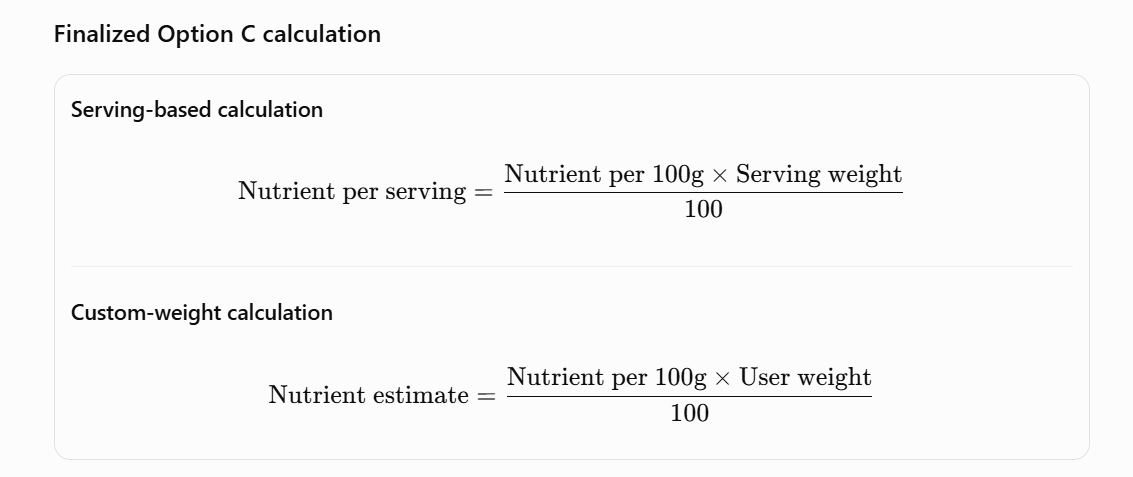

The application will support both:
1. Serving-based calculation: Number of servings × nutrition per serving.
2. Custom-weight calculation: Enter grams × nutrition per 100g ÷ 100.

### Step 7 — Calculate standardized per-serving nutrition

It creates a new DataFrame and preserves the original source per-serving values in separate columns. It does not modify the original Excel workbook or the classifier.

In [14]:

# Step 7: Apply standardized serving weights and calculate per-serving nutrition

serving_weights = {
    "masala_dosa": 250,
    "butter_naan": 60,
    "burger": 150,
    "chai": 200,
    "chapati": 40,
    "chole_bhature": 350,
    "idli": 40,
    "dal_makhani": 200,
    "dhokla": 40,
    "fried_rice": 250,
    "kaathi_rolls": 200,
    "paani_puri": 150,
    "pav_bhaji": 300,
    "kadai_paneer": 200,
    "kulfi": 80,
    "pakode": 150,
    "pizza": 100,
    "samosa": 100,
    "jalebi": 30,
    "momos": 180
}

# Create a separate final working copy
nutrition_final_df = nutrition_working_df.copy()

# Preserve the original per-serving source values
serving_columns = [
    "unit_serving_energy_kcal",
    "unit_serving_carb_g",
    "unit_serving_protein_g",
    "unit_serving_fat_g",
    "unit_serving_fibre_g"
]

for col in serving_columns:
    nutrition_final_df[f"{col}_source"] = nutrition_final_df[col]

# Add standardized serving weights
nutrition_final_df["standard_serving_weight_g"] = (
    nutrition_final_df["food_name"].map(serving_weights)
)

# Calculate standardized per-serving nutrition from per-100g values
nutrient_mapping = {
    "energy_kcal": "unit_serving_energy_kcal",
    "carb_g": "unit_serving_carb_g",
    "protein_g": "unit_serving_protein_g",
    "fat_g": "unit_serving_fat_g",
    "fibre_g": "unit_serving_fibre_g"
}

for source_col, target_col in nutrient_mapping.items():
    nutrition_final_df[target_col] = (
        nutrition_final_df[source_col]
        * nutrition_final_df["standard_serving_weight_g"]
        / 100
    )

# Check that all 20 dishes received a serving weight
print("Total dishes:", len(nutrition_final_df))
print(
    "Missing serving weights:",
    nutrition_final_df["standard_serving_weight_g"].isna().sum()
)

display(
    nutrition_final_df[
        [
            "food_name",
            "servings_unit",
            "standard_serving_weight_g",
            "unit_serving_energy_kcal",
            "unit_serving_protein_g",
            "unit_serving_carb_g",
            "unit_serving_fat_g"
        ]
    ].round(2)
)


Total dishes: 20
Missing serving weights: 0


,food_name,servings_unit,standard_serving_weight_g,unit_serving_energy_kcal,unit_serving_protein_g,unit_serving_carb_g,unit_serving_fat_g
0,masala_dosa,dosa,250,411.46,8.22,48.92,19.60
1,butter_naan,naan,60,171.87,4.83,31.05,2.99
2,burger,burger,150,779.90,4.89,20.53,75.95
3,chai,tea cup,200,32.29,0.78,5.16,1.06
4,chapati,chapati,40,80.92,2.35,14.26,1.42
5,chole_bhature,bhatura,350,2776.21,5.71,37.57,288.97
6,idli,idli,40,55.01,1.85,11.27,0.13
7,dal_makhani,bowl,200,148.08,6.63,15.92,6.13
8,dhokla,piece,40,86.59,5.38,12.27,2.11
9,fried_rice,plate,250,301.46,10.13,33.50,13.59


In [15]:

# Step 8: Identify unusually high per-100g nutrition values

check_columns = [
    "energy_kcal",
    "protein_g",
    "carb_g",
    "fat_g"
]

display(
    nutrition_final_df[
        ["food_name", "mapping_type"] + check_columns
    ].sort_values(
        by="energy_kcal",
        ascending=False
    ).round(2)
)


,food_name,mapping_type,energy_kcal,protein_g,carb_g,fat_g
5,chole_bhature,INDB,793.20,1.63,10.73,82.56
15,pakode,INDB,677.19,1.90,6.04,71.84
19,momos,Proxy,673.81,1.94,5.12,71.86
17,samosa,INDB,577.39,1.71,9.21,59.19
2,burger,INDB,519.93,3.26,13.69,50.63
11,paani_puri,INDB,509.89,3.52,16.47,47.91
1,butter_naan,INDB,286.45,8.05,51.75,4.99
10,kaathi_rolls,INDB,285.94,6.92,20.10,19.55
8,dhokla,INDB,216.49,13.45,30.68,5.28
4,chapati,INDB,202.31,5.88,35.65,3.56


### Step 7 – Standardization of Serving Weights and Per-Serving Nutrition

- Defined approximate standard serving weights for all 20 food categories to provide a consistent basis for nutrition estimation.
- Successfully mapped serving weights to all 20 dishes, with no missing values.
- Calculated per-serving calories, protein, carbohydrates, fat and fibre using the corresponding per-100g nutritional values.
- Preserved the original source per-serving values separately for comparison.
- These standardized serving weights are approximate assumptions intended for application-level estimation.

### Step 8 – Validation of Per-100g Nutritional Values

- Reviewed per-100g calorie and macronutrient values across all 20 food categories.
- Identified unusually high energy and fat values in certain dishes, particularly Chole Bhature, Pakode, Momos, Samosa, Burger and Paani Puri.
- These values significantly influence the calculated per-serving nutritional estimates.
- The calculation logic was verified, but some source nutritional values may require further validation.
- The existing values have been retained without modification to preserve the original dataset.